In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/raw/cfb_schedules_2026.csv")

In [4]:
df.head()

,game_id,season,week,season_type,season_type_id,start_date,start_time_tbd,completed,neutral_site,conference_game,...,highlights,notes,playoff_competition,playoff_format,playoff_round,playoff_round_name,playoff_bracket_slot,playoff_home_seed,playoff_away_seed,playoff_bowl_name
0,401856634,2026,1,regular,2,2026-09-05T16:00:00.000Z,False,True,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,401856635,2026,1,regular,2,2026-09-05T20:15:00.000Z,False,True,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,401856636,2026,1,regular,2,2026-09-05T19:30:00.000Z,False,True,True,False,...,NaN,Aflac Kickoff,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,401856637,2026,1,regular,2,2026-09-05T23:45:00.000Z,False,True,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,401856658,2026,1,regular,2,2026-09-05T19:00:00.000Z,False,True,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.columns

Index(['game_id', 'season', 'week', 'season_type', 'season_type_id',
       'start_date', 'start_time_tbd', 'completed', 'neutral_site',
       'conference_game', 'conference_competition', 'attendance', 'venue_id',
       'venue', 'status', 'home_id', 'home_team', 'home_abbreviation',
       'home_division', 'home_conference', 'home_points', 'home_winner',
       'away_id', 'away_team', 'away_abbreviation', 'away_division',
       'away_conference', 'away_points', 'away_winner', 'fbs_game',
       'fbs_participant', 'highlights', 'notes', 'playoff_competition',
       'playoff_format', 'playoff_round', 'playoff_round_name',
       'playoff_bracket_slot', 'playoff_home_seed', 'playoff_away_seed',
       'playoff_bowl_name'],
      dtype='str')

In [6]:
df.shape

(3679, 41)

In [7]:
df['fbs_game'].value_counts()

fbs_game
False    2918
True      761
Name: count, dtype: int64

In [8]:
fbs = df[df['fbs_game'] == True].copy()

In [9]:
fbs.shape

(761, 41)

In [16]:
fbs[['home_team', 'away_team', 'home_points', 'away_points', 'home_winner']].head(10)

,home_team,away_team,home_points,away_points,home_winner
0,Alabama,East Carolina,48.0,10.0,True
2,Auburn,Baylor,17.0,16.0,True
3,Florida,Florida Atlantic,66.0,21.0,True
6,LSU,Clemson,51.0,10.0,True
7,Ole Miss,Louisville,41.0,38.0,True
8,Mississippi State,UL Monroe,62.0,13.0,True
10,Oklahoma,UTEP,51.0,0.0,True
11,South Carolina,Kent State,57.0,0.0,True
13,Texas,Texas State,59.0,7.0,True
14,Texas A&M,Missouri State,50.0,0.0,True


In [12]:
fbs = fbs.dropna(subset=['home_winner']).copy()

In [13]:
fbs['home_win'] = fbs['home_winner'].astype(int)

In [17]:
fbs[['home_team', 'away_team', 'home_points', 'away_points', 'home_win']].head(10)

,home_team,away_team,home_points,away_points,home_win
0,Alabama,East Carolina,48.0,10.0,1
2,Auburn,Baylor,17.0,16.0,1
3,Florida,Florida Atlantic,66.0,21.0,1
6,LSU,Clemson,51.0,10.0,1
7,Ole Miss,Louisville,41.0,38.0,1
8,Mississippi State,UL Monroe,62.0,13.0,1
10,Oklahoma,UTEP,51.0,0.0,1
11,South Carolina,Kent State,57.0,0.0,1
13,Texas,Texas State,59.0,7.0,1
14,Texas A&M,Missouri State,50.0,0.0,1


In [18]:
fbs.shape

(157, 42)

In [19]:
fbs['home_win'].value_counts()

home_win
1    115
0     42
Name: count, dtype: int64

In [20]:
fbs[['home_points', 'away_points']].isna().sum()

home_points    0
away_points    0
dtype: int64

In [21]:
teams = pd.unique(
    pd.concat([fbs['home_team'], fbs['away_team']])
)

len(teams)

138

In [22]:
teams[:20]

<ArrowStringArray>
[          'Alabama',            'Auburn',           'Florida',
               'LSU',          'Ole Miss', 'Mississippi State',
          'Oklahoma',    'South Carolina',             'Texas',
         'Texas A&M',              'Utah',           'Georgia',
          'Kentucky',         'Minnesota',            'Kansas',
          'Michigan',      'Georgia Tech',        'Vanderbilt',
          'Arkansas',          'Missouri']
Length: 20, dtype: str

In [23]:
fbs = fbs.sort_values('start_date').copy()

In [24]:
fbs[['start_date', 'week', 'home_team', 'away_team']].head(10)

,start_date,week,home_team,away_team
110,2026-08-29T16:00:00.000Z,1,TCU,North Carolina
621,2026-08-29T19:00:00.000Z,1,USC,San José State
234,2026-08-29T19:30:00.000Z,1,Virginia,NC State
683,2026-08-29T21:30:00.000Z,1,North Dakota State,Jacksonville State
687,2026-08-29T22:30:00.000Z,1,Eastern Michigan,Sacramento State
233,2026-08-29T23:00:00.000Z,1,Stanford,Hawai'i
677,2026-08-29T23:00:00.000Z,1,Florida State,New Mexico State
529,2026-08-30T02:00:00.000Z,1,UNLV,Memphis
348,2026-09-03T22:00:00.000Z,1,Rutgers,Massachusetts
235,2026-09-03T23:00:00.000Z,1,Wake Forest,Akron


In [25]:
home_games = fbs[['start_date', 'week', 'home_team', 'away_team',
                  'home_points', 'away_points', 'neutral_site']].copy()

home_games.columns = [
    'date', 'week', 'team', 'opponent',
    'points_for', 'points_against', 'neutral_site'
]

In [26]:
away_games = fbs[['start_date', 'week', 'away_team', 'home_team',
                  'away_points', 'home_points', 'neutral_site']].copy()

away_games.columns = [
    'date', 'week', 'team', 'opponent',
    'points_for', 'points_against', 'neutral_site'
]

In [27]:
team_games = pd.concat([home_games, away_games], ignore_index=True)

In [29]:
team_games.head(2)

,date,week,team,opponent,points_for,points_against,neutral_site
0,2026-08-29T16:00:00.000Z,1,TCU,North Carolina,10.0,15.0,True
1,2026-08-29T19:00:00.000Z,1,USC,San José State,42.0,26.0,False


In [30]:
team_games[team_games['date'] == team_games['date'].iloc[0]].head()

,date,week,team,opponent,points_for,points_against,neutral_site
0,2026-08-29T16:00:00.000Z,1,TCU,North Carolina,10.0,15.0,True
157,2026-08-29T16:00:00.000Z,1,North Carolina,TCU,15.0,10.0,True


In [31]:
team_games.head(10)

,date,week,team,opponent,points_for,points_against,neutral_site
0,2026-08-29T16:00:00.000Z,1,TCU,North Carolina,10.0,15.0,True
1,2026-08-29T19:00:00.000Z,1,USC,San José State,42.0,26.0,False
2,2026-08-29T19:30:00.000Z,1,Virginia,NC State,34.0,8.0,False
3,2026-08-29T21:30:00.000Z,1,North Dakota State,Jacksonville State,33.0,7.0,False
4,2026-08-29T22:30:00.000Z,1,Eastern Michigan,Sacramento State,28.0,17.0,False
5,2026-08-29T23:00:00.000Z,1,Stanford,Hawai'i,37.0,27.0,False
6,2026-08-29T23:00:00.000Z,1,Florida State,New Mexico State,34.0,17.0,False
7,2026-08-30T02:00:00.000Z,1,UNLV,Memphis,21.0,27.0,False
8,2026-09-03T22:00:00.000Z,1,Rutgers,Massachusetts,21.0,37.0,False
9,2026-09-03T23:00:00.000Z,1,Wake Forest,Akron,38.0,16.0,False


In [32]:
team_games = team_games.sort_values('date').reset_index(drop=True)

In [33]:
team_games.head(10)

,date,week,team,opponent,points_for,points_against,neutral_site
0,2026-08-29T16:00:00.000Z,1,TCU,North Carolina,10.0,15.0,True
1,2026-08-29T16:00:00.000Z,1,North Carolina,TCU,15.0,10.0,True
2,2026-08-29T19:00:00.000Z,1,USC,San José State,42.0,26.0,False
3,2026-08-29T19:00:00.000Z,1,San José State,USC,26.0,42.0,False
4,2026-08-29T19:30:00.000Z,1,Virginia,NC State,34.0,8.0,False
5,2026-08-29T19:30:00.000Z,1,NC State,Virginia,8.0,34.0,False
6,2026-08-29T21:30:00.000Z,1,North Dakota State,Jacksonville State,33.0,7.0,False
7,2026-08-29T21:30:00.000Z,1,Jacksonville State,North Dakota State,7.0,33.0,False
8,2026-08-29T22:30:00.000Z,1,Eastern Michigan,Sacramento State,28.0,17.0,False
9,2026-08-29T22:30:00.000Z,1,Sacramento State,Eastern Michigan,17.0,28.0,False


In [34]:
team_games.shape

(314, 7)

In [35]:
team_games['point_diff'] = team_games['points_for'] - team_games['points_against']

In [36]:
team_games[['team', 'opponent', 'points_for', 'points_against', 'point_diff']].head(10)

,team,opponent,points_for,points_against,point_diff
0,TCU,North Carolina,10.0,15.0,-5.0
1,North Carolina,TCU,15.0,10.0,5.0
2,USC,San José State,42.0,26.0,16.0
3,San José State,USC,26.0,42.0,-16.0
4,Virginia,NC State,34.0,8.0,26.0
5,NC State,Virginia,8.0,34.0,-26.0
6,North Dakota State,Jacksonville State,33.0,7.0,26.0
7,Jacksonville State,North Dakota State,7.0,33.0,-26.0
8,Eastern Michigan,Sacramento State,28.0,17.0,11.0
9,Sacramento State,Eastern Michigan,17.0,28.0,-11.0


In [37]:
team_games['games_played'] = team_games.groupby('team').cumcount()

In [39]:
team_games[['date', 'team', 'opponent', 'point_diff', 'games_played']].head(15)

,date,team,opponent,point_diff,games_played
0,2026-08-29T16:00:00.000Z,TCU,North Carolina,-5.0,0
1,2026-08-29T16:00:00.000Z,North Carolina,TCU,5.0,0
2,2026-08-29T19:00:00.000Z,USC,San José State,16.0,0
3,2026-08-29T19:00:00.000Z,San José State,USC,-16.0,0
4,2026-08-29T19:30:00.000Z,Virginia,NC State,26.0,0
5,2026-08-29T19:30:00.000Z,NC State,Virginia,-26.0,0
6,2026-08-29T21:30:00.000Z,North Dakota State,Jacksonville State,26.0,0
7,2026-08-29T21:30:00.000Z,Jacksonville State,North Dakota State,-26.0,0
8,2026-08-29T22:30:00.000Z,Eastern Michigan,Sacramento State,11.0,0
9,2026-08-29T22:30:00.000Z,Sacramento State,Eastern Michigan,-11.0,0


In [40]:
team_games['prior_point_diff'] = (
    team_games.groupby('team')['point_diff']
    .transform(lambda x: x.shift().expanding().mean())
)

In [41]:
team_games[['team', 'opponent', 'point_diff', 'games_played', 'prior_point_diff']].head(15)

,team,opponent,point_diff,games_played,prior_point_diff
0,TCU,North Carolina,-5.0,0,NaN
1,North Carolina,TCU,5.0,0,NaN
2,USC,San José State,16.0,0,NaN
3,San José State,USC,-16.0,0,NaN
4,Virginia,NC State,26.0,0,NaN
5,NC State,Virginia,-26.0,0,NaN
6,North Dakota State,Jacksonville State,26.0,0,NaN
7,Jacksonville State,North Dakota State,-26.0,0,NaN
8,Eastern Michigan,Sacramento State,11.0,0,NaN
9,Sacramento State,Eastern Michigan,-11.0,0,NaN


In [42]:
team_games[team_games['team'] == 'Auburn'][[
    'date',
    'week',
    'team',
    'opponent',
    'point_diff',
    'games_played',
    'prior_point_diff'
]]

,date,week,team,opponent,point_diff,games_played,prior_point_diff
52,2026-09-05T19:30:00.000Z,1,Auburn,Baylor,1.0,0,NaN
186,2026-09-12T23:45:00.000Z,2,Auburn,Southern Miss,35.0,1,1.0
266,2026-09-19T23:00:00.000Z,3,Auburn,Florida,-5.0,2,18.0


In [43]:
team_games[team_games['team'] == 'Alabama'][[
    'date',
    'week',
    'team',
    'opponent',
    'point_diff',
    'games_played',
    'prior_point_diff'
]]

,date,week,team,opponent,point_diff,games_played,prior_point_diff
34,2026-09-05T16:00:00.000Z,1,Alabama,East Carolina,38.0,0,NaN
138,2026-09-12T19:30:00.000Z,2,Alabama,Kentucky,28.0,1,38.0
234,2026-09-19T19:30:00.000Z,3,Alabama,Florida State,14.0,2,33.0


In [44]:
fbs['home_field'] = (~fbs['neutral_site']).astype(int)

In [45]:
fbs[['home_team', 'away_team', 'neutral_site', 'home_field']].head(10)

,home_team,away_team,neutral_site,home_field
110,TCU,North Carolina,True,0
621,USC,San José State,False,1
234,Virginia,NC State,False,1
683,North Dakota State,Jacksonville State,False,1
687,Eastern Michigan,Sacramento State,False,1
233,Stanford,Hawai'i,False,1
677,Florida State,New Mexico State,False,1
529,UNLV,Memphis,False,1
348,Rutgers,Massachusetts,False,1
235,Wake Forest,Akron,False,1


In [46]:
home_features = team_games[['date', 'team', 'opponent', 'prior_point_diff']].copy()

home_features = home_features.rename(columns={
    'team': 'home_team',
    'opponent': 'away_team',
    'prior_point_diff': 'home_prior_point_diff'
})

In [47]:
away_features = team_games[['date', 'team', 'opponent', 'prior_point_diff']].copy()

away_features = away_features.rename(columns={
    'team': 'away_team',
    'opponent': 'home_team',
    'prior_point_diff': 'away_prior_point_diff'
})

In [48]:
games_model = fbs.merge(
    home_features,
    left_on=['start_date', 'home_team', 'away_team'],
    right_on=['date', 'home_team', 'away_team'],
    how='left'
)

In [49]:
games_model = games_model.merge(
    away_features,
    left_on=['start_date', 'home_team', 'away_team'],
    right_on=['date', 'home_team', 'away_team'],
    how='left',
    suffixes=('', '_away')
)

In [50]:
games_model[['home_team', 'away_team',
             'home_prior_point_diff',
             'away_prior_point_diff',
             'home_win']].head(15)

,home_team,away_team,home_prior_point_diff,away_prior_point_diff,home_win
0,TCU,North Carolina,NaN,NaN,0
1,USC,San José State,NaN,NaN,1
2,Virginia,NC State,NaN,NaN,1
3,North Dakota State,Jacksonville State,NaN,NaN,1
4,Eastern Michigan,Sacramento State,NaN,NaN,1
5,Stanford,Hawai'i,NaN,NaN,1
6,Florida State,New Mexico State,NaN,NaN,1
7,UNLV,Memphis,NaN,NaN,0
8,Rutgers,Massachusetts,NaN,NaN,0
9,Wake Forest,Akron,NaN,NaN,1


In [51]:
games_model['prior_diff_difference'] = (
    games_model['home_prior_point_diff']
    - games_model['away_prior_point_diff']
)

In [52]:
games_model[[
    'home_team',
    'away_team',
    'home_prior_point_diff',
    'away_prior_point_diff',
    'prior_diff_difference',
    'home_field',
    'home_win'
]].head(15)

,home_team,away_team,home_prior_point_diff,away_prior_point_diff,prior_diff_difference,home_field,home_win
0,TCU,North Carolina,NaN,NaN,NaN,0,0
1,USC,San José State,NaN,NaN,NaN,1,1
2,Virginia,NC State,NaN,NaN,NaN,1,1
3,North Dakota State,Jacksonville State,NaN,NaN,NaN,1,1
4,Eastern Michigan,Sacramento State,NaN,NaN,NaN,1,1
5,Stanford,Hawai'i,NaN,NaN,NaN,1,1
6,Florida State,New Mexico State,NaN,NaN,NaN,1,1
7,UNLV,Memphis,NaN,NaN,NaN,1,0
8,Rutgers,Massachusetts,NaN,NaN,NaN,1,0
9,Wake Forest,Akron,NaN,NaN,NaN,1,1


In [54]:
talent = pd.read_parquet("../data/raw/cfb_team_talent_2026.parquet")

In [56]:
talent.shape
talent.columns

Index(['season', 'team_id', 'team', 'talent_composite', 'talent_rank',
       'blue_chip_ratio', 'n_recruits'],
      dtype='str')

In [57]:
talent.shape

(312, 7)

In [58]:
talent.head(10)

,season,team_id,team,talent_composite,talent_rank,blue_chip_ratio,n_recruits
0,2026,61,Georgia Bulldogs,1454.717534,1,0.730435,115
1,2026,333,Alabama Crimson Tide,1451.391106,2,0.616071,112
2,2026,251,Texas Longhorns,1404.970025,3,0.606061,99
3,2026,2483,Oregon Ducks,1401.609491,4,0.537815,119
4,2026,194,Ohio State Buckeyes,1367.142473,5,0.603960,101
5,2026,87,Notre Dame Fighting Irish,1331.291012,6,0.653846,104
6,2026,245,Texas A&M Aggies,1292.792813,7,0.707865,89
7,2026,30,USC Trojans,1275.932561,8,0.472727,110
8,2026,99,LSU Tigers,1272.669430,9,0.509804,102
9,2026,2390,Miami Hurricanes,1262.928850,10,0.523364,107


In [60]:
games_model['home_id'].dtype

dtype('int64')

In [61]:
home_talent['home_id'].dtype

<StringDtype(na_value=nan)>

In [62]:
home_talent['home_id'] = home_talent['home_id'].astype(int)

In [63]:
games_model = games_model.merge(
    home_talent,
    on='home_id',
    how='left'
)

In [64]:
games_model[['home_team', 'home_id', 'home_talent']].head(10)

,home_team,home_id,home_talent
0,TCU,2628,977.958755
1,USC,30,1275.932561
2,Virginia,258,681.785176
3,North Dakota State,2449,645.189627
4,Eastern Michigan,2199,776.762669
5,Stanford,24,892.668904
6,Florida State,52,1140.327182
7,UNLV,2439,727.914801
8,Rutgers,164,974.556762
9,Wake Forest,154,817.833243


In [65]:
away_talent = talent[['team_id', 'talent_composite']].copy()

away_talent = away_talent.rename(columns={
    'team_id': 'away_id',
    'talent_composite': 'away_talent'
})

away_talent['away_id'] = away_talent['away_id'].astype(int)

In [66]:
games_model = games_model.merge(
    away_talent,
    on='away_id',
    how='left'
)

In [67]:
games_model[['home_team', 'away_team', 'home_talent', 'away_talent']].head(10)

,home_team,away_team,home_talent,away_talent
0,TCU,North Carolina,977.958755,964.935793
1,USC,San José State,1275.932561,724.163054
2,Virginia,NC State,681.785176,940.014330
3,North Dakota State,Jacksonville State,645.189627,675.348556
4,Eastern Michigan,Sacramento State,776.762669,692.998807
5,Stanford,Hawai'i,892.668904,NaN
6,Florida State,New Mexico State,1140.327182,642.117836
7,UNLV,Memphis,727.914801,811.136894
8,Rutgers,Massachusetts,974.556762,580.069774
9,Wake Forest,Akron,817.833243,633.611512


In [68]:
games_model['talent_difference'] = (
    games_model['home_talent'] - games_model['away_talent']
)

In [69]:
games_model[[
    'home_team',
    'away_team',
    'home_talent',
    'away_talent',
    'talent_difference'
]].head(10)

,home_team,away_team,home_talent,away_talent,talent_difference
0,TCU,North Carolina,977.958755,964.935793,13.022962
1,USC,San José State,1275.932561,724.163054,551.769507
2,Virginia,NC State,681.785176,940.014330,-258.229154
3,North Dakota State,Jacksonville State,645.189627,675.348556,-30.158929
4,Eastern Michigan,Sacramento State,776.762669,692.998807,83.763862
5,Stanford,Hawai'i,892.668904,NaN,NaN
6,Florida State,New Mexico State,1140.327182,642.117836,498.209345
7,UNLV,Memphis,727.914801,811.136894,-83.222093
8,Rutgers,Massachusetts,974.556762,580.069774,394.486989
9,Wake Forest,Akron,817.833243,633.611512,184.221731


In [70]:
games_model[[
    'home_team',
    'away_team',
    'prior_diff_difference',
    'talent_difference',
    'home_field',
    'home_win'
]].head(10)

,home_team,away_team,prior_diff_difference,talent_difference,home_field,home_win
0,TCU,North Carolina,NaN,13.022962,0,0
1,USC,San José State,NaN,551.769507,1,1
2,Virginia,NC State,NaN,-258.229154,1,1
3,North Dakota State,Jacksonville State,NaN,-30.158929,1,1
4,Eastern Michigan,Sacramento State,NaN,83.763862,1,1
5,Stanford,Hawai'i,NaN,NaN,1,1
6,Florida State,New Mexico State,NaN,498.209345,1,1
7,UNLV,Memphis,NaN,-83.222093,1,0
8,Rutgers,Massachusetts,NaN,394.486989,1,0
9,Wake Forest,Akron,NaN,184.221731,1,1


In [71]:
team_games['prior_3_game_diff'] = (
    team_games.groupby('team')['point_diff']
    .transform(lambda x: x.shift(1).rolling(3, min_periods=1).mean())
)

In [72]:
team_games[team_games['team'] == 'Auburn'][[
    'date',
    'week',
    'point_diff',
    'prior_3_game_diff'
]]

,date,week,point_diff,prior_3_game_diff
52,2026-09-05T19:30:00.000Z,1,1.0,NaN
186,2026-09-12T23:45:00.000Z,2,35.0,1.0
266,2026-09-19T23:00:00.000Z,3,-5.0,18.0


In [73]:
home_form = team_games[['date', 'team', 'opponent', 'prior_3_game_diff']].copy()

home_form = home_form.rename(columns={
    'team': 'home_team',
    'opponent': 'away_team',
    'prior_3_game_diff': 'home_prior_3_game_diff'
})

In [74]:
away_form = team_games[['date', 'team', 'opponent', 'prior_3_game_diff']].copy()

away_form = away_form.rename(columns={
    'team': 'away_team',
    'opponent': 'home_team',
    'prior_3_game_diff': 'away_prior_3_game_diff'
})

In [75]:
games_model = games_model.merge(
    home_form,
    left_on=['start_date', 'home_team', 'away_team'],
    right_on=['date', 'home_team', 'away_team'],
    how='left'
)

games_model = games_model.merge(
    away_form,
    left_on=['start_date', 'home_team', 'away_team'],
    right_on=['date', 'home_team', 'away_team'],
    how='left',
    suffixes=('', '_away')
)

In [76]:
games_model['recent_form_difference'] = (
    games_model['home_prior_3_game_diff']
    - games_model['away_prior_3_game_diff']
)

In [77]:
games_model[[
    'home_team',
    'away_team',
    'prior_diff_difference',
    'recent_form_difference',
    'talent_difference',
    'home_field',
    'home_win'
]].head(15)

,home_team,away_team,prior_diff_difference,recent_form_difference,talent_difference,home_field,home_win
0,TCU,North Carolina,NaN,NaN,13.022962,0,0
1,USC,San José State,NaN,NaN,551.769507,1,1
2,Virginia,NC State,NaN,NaN,-258.229154,1,1
3,North Dakota State,Jacksonville State,NaN,NaN,-30.158929,1,1
4,Eastern Michigan,Sacramento State,NaN,NaN,83.763862,1,1
5,Stanford,Hawai'i,NaN,NaN,NaN,1,1
6,Florida State,New Mexico State,NaN,NaN,498.209345,1,1
7,UNLV,Memphis,NaN,NaN,-83.222093,1,0
8,Rutgers,Massachusetts,NaN,NaN,394.486989,1,0
9,Wake Forest,Akron,NaN,NaN,184.221731,1,1


In [78]:
games_model[[
    'prior_diff_difference',
    'recent_form_difference',
    'talent_difference'
]].isna().sum()

prior_diff_difference     86
recent_form_difference    86
talent_difference          3
dtype: int64

In [79]:
games_model['prior_diff_difference'] = (
    games_model['prior_diff_difference'].fillna(0)
)

games_model['recent_form_difference'] = (
    games_model['recent_form_difference'].fillna(0)
)

In [80]:
games_model[[
    'prior_diff_difference',
    'recent_form_difference',
    'talent_difference'
]].isna().sum()

prior_diff_difference     0
recent_form_difference    0
talent_difference         3
dtype: int64

In [81]:
games_model[
    games_model['talent_difference'].isna()
][[
    'home_team',
    'away_team',
    'home_talent',
    'away_talent'
]]

,home_team,away_team,home_talent,away_talent
5,Stanford,Hawai'i,892.668904,NaN
43,Hawai'i,UNLV,NaN,727.914801
99,Hawai'i,New Mexico State,NaN,642.117836


In [82]:
model_data = games_model.dropna(
    subset=[
        'prior_diff_difference',
        'recent_form_difference',
        'talent_difference'
    ]
).copy()

In [83]:
model_data.shape

(154, 56)

In [84]:
features = [
    'prior_diff_difference',
    'recent_form_difference',
    'talent_difference',
    'home_field'
]

X = model_data[features]
y = model_data['home_win']

In [85]:
split = int(len(model_data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training games:", len(X_train))
print("Testing games:", len(X_test))

Training games: 123
Testing games: 31


In [86]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

ModuleNotFoundError: No module named 'sklearn'

In [87]:
import sys
print(sys.executable)

c:\Users\rgeor\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [88]:
import sys
!{sys.executable} -m pip install scikit-learn

In [89]:
import sklearn
print(sklearn.__version__)

1.9.1


In [90]:
from sklearn.linear_model import LogisticRegression

In [91]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [92]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Test accuracy:", accuracy)

Test accuracy: 0.6451612903225806


In [93]:
y_prob = model.predict_proba(X_test)[:, 1]

print(y_prob[:10])

[0.60531392 0.85289828 0.83786972 0.76033837 0.73710155 0.74286163
 0.6006969  0.60819509 0.88962547 0.75535473]


In [94]:
test_results = model_data.iloc[split:].copy()

test_results['predicted_home_win_prob'] = y_prob

test_results['predicted_home_win'] = y_pred

In [95]:
test_results[[
    'home_team',
    'away_team',
    'home_win',
    'predicted_home_win_prob',
    'predicted_home_win'
]].head(10)

,home_team,away_team,home_win,predicted_home_win_prob,predicted_home_win
126,Liberty,Ball State,1,0.605314,1
127,Baylor,Louisiana Tech,1,0.852898,1
128,South Carolina,Mississippi State,0,0.837870,1
129,Old Dominion,East Carolina,0,0.760338,1
130,Florida Atlantic,Florida International,1,0.737102,1
131,App State,Charlotte,1,0.742862,1
132,Missouri State,Marshall,0,0.600697,1
133,Auburn,Florida,0,0.608195,1
134,Missouri,Troy,1,0.889625,1
135,UCF,Georgia State,1,0.755355,1


In [96]:
from sklearn.metrics import log_loss

loss = log_loss(y_test, y_prob)

print("Test log loss:", loss)

Test log loss: 0.6483294286144549


In [97]:
baseline_prob = y_train.mean()

print("Baseline home-win probability:", baseline_prob)

Baseline home-win probability: 0.7642276422764228


In [98]:
baseline_log_loss = log_loss(
    y_test,
    [baseline_prob] * len(y_test)
)

print("Baseline log loss:", baseline_log_loss)

Baseline log loss: 0.7241149739863607


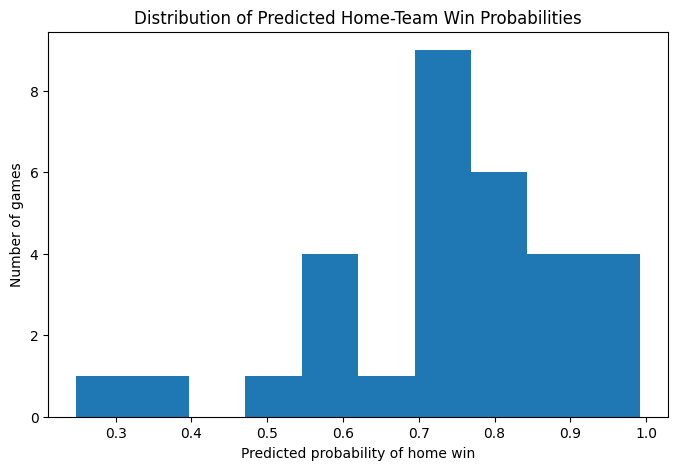

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(y_prob, bins=10)

plt.xlabel("Predicted probability of home win")
plt.ylabel("Number of games")
plt.title("Distribution of Predicted Home-Team Win Probabilities")

plt.show()

In [100]:
test_results['probability_bin'] = pd.cut(
    test_results['predicted_home_win_prob'],
    bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    include_lowest=True
)

calibration = test_results.groupby(
    'probability_bin',
    observed=False
).agg(
    predicted_probability=('predicted_home_win_prob', 'mean'),
    actual_win_rate=('home_win', 'mean'),
    games=('home_win', 'count')
)

calibration

,predicted_probability,actual_win_rate,games
probability_bin,,,
"(-0.001, 0.5]",0.377287,0.333333,3
"(0.5, 0.6]",0.568203,1.000000,1
"(0.6, 0.7]",0.614410,0.500000,4
"(0.7, 0.8]",0.742511,0.545455,11
"(0.8, 0.9]",0.844852,0.625000,8
"(0.9, 1.0]",0.981097,1.000000,4


In [101]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/raw")

schedule_files = sorted(data_path.glob("cfb_schedule*.csv"))
talent_files = sorted(data_path.glob("cfb_team_talent_*.parquet"))
recruiting_files = sorted(data_path.glob("cfb_recruits_*.parquet"))
returning_files = sorted(data_path.glob("cfb_returning_production_*.parquet"))

print("Schedule files:", len(schedule_files))
print("Talent files:", len(talent_files))
print("Recruiting files:", len(recruiting_files))
print("Returning production files:", len(returning_files))

Schedule files: 6
Talent files: 6
Recruiting files: 6
Returning production files: 6


In [102]:
from pathlib import Path

data_path = Path("../data/raw")

files = list(data_path.iterdir())

schedule_files = [
    f for f in files
    if "schedule" in f.name.lower() and f.suffix == ".csv"
]

talent_files = [
    f for f in files
    if "team_talent" in f.name.lower() and f.suffix == ".parquet"
]

recruiting_files = [
    f for f in files
    if "recruits" in f.name.lower() and f.suffix == ".parquet"
]

returning_files = [
    f for f in files
    if "returning_production" in f.name.lower() and f.suffix == ".parquet"
]

print("Schedule files:", len(schedule_files))
print("Talent files:", len(talent_files))
print("Recruiting files:", len(recruiting_files))
print("Returning production files:", len(returning_files))

Schedule files: 6
Talent files: 6
Recruiting files: 6
Returning production files: 6


In [103]:
# Load all schedule files
schedules = []

for file in schedule_files:
    temp = pd.read_csv(file)
    schedules.append(temp)

all_schedules = pd.concat(schedules, ignore_index=True)


# Load all team talent files
talents = []

for file in talent_files:
    temp = pd.read_parquet(file)
    talents.append(temp)

all_talent = pd.concat(talents, ignore_index=True)


# Load all recruiting files
recruiting = []

for file in recruiting_files:
    temp = pd.read_parquet(file)
    recruiting.append(temp)

all_recruiting = pd.concat(recruiting, ignore_index=True)


# Load all returning production files
returning_production = []

for file in returning_files:
    temp = pd.read_parquet(file)
    returning_production.append(temp)

all_returning_production = pd.concat(
    returning_production,
    ignore_index=True
)


print("Schedules:", all_schedules.shape)
print("Talent:", all_talent.shape)
print("Recruiting:", all_recruiting.shape)
print("Returning production:", all_returning_production.shape)

Schedules: (8313, 44)
Talent: (1874, 7)
Recruiting: (23815, 9)
Returning production: (1314, 9)


In [104]:
print("TALENT COLUMNS:")
print(all_talent.columns.tolist())

print("\nRECRUITING COLUMNS:")
print(all_recruiting.columns.tolist())

print("\nRETURNING PRODUCTION COLUMNS:")
print(all_returning_production.columns.tolist())

TALENT COLUMNS:
['season', 'team_id', 'team', 'talent_composite', 'talent_rank', 'blue_chip_ratio', 'n_recruits']

RECRUITING COLUMNS:
['season', 'team_id', 'team_id_247', 'team', 'recruit_id', 'player_name', 'stars', 'grade', 'position']

RETURNING PRODUCTION COLUMNS:
['season', 'team_id', 'off_returning', 'def_returning', 'overall_returning', 'n_returning', 'is_estimated', 'def_basis', 'overall_basis']


In [105]:
print("RETURNING PRODUCTION COLUMNS:")
print(all_returning_production.columns.tolist())

print("\nRECRUITING SAMPLE:")
print(all_recruiting.head())

print("\nTALENT SAMPLE:")
print(all_talent.head())

print("\nRETURNING PRODUCTION SAMPLE:")
print(all_returning_production.head())

RETURNING PRODUCTION COLUMNS:
['season', 'team_id', 'off_returning', 'def_returning', 'overall_returning', 'n_returning', 'is_estimated', 'def_basis', 'overall_basis']

RECRUITING SAMPLE:
   season team_id team_id_247                       team recruit_id  \
0    2021     326         290        Texas State Bobcats   46102116   
1    2021    2390          13           Miami Hurricanes   46042613   
2    2021     154          23  Wake Forest Demon Deacons   46111961   
3    2021      38          27         Colorado Buffaloes   46081401   
4    2021      66          29        Iowa State Cyclones   46100843   

        player_name  stars  grade position  
0   Devarrick Woods    3.0   86.0       DL  
1  Laurence Seymore    3.0   87.0      IOL  
2    Horatio Fields    4.0   90.0       WR  
3       Ty Robinson    3.0   85.0      ATH  
4     Myles Norwood    3.0   88.0       CB  

TALENT SAMPLE:
   season team_id                  team  talent_composite  talent_rank  \
0    2021      61      Ge

In [106]:
recruiting_summary = (
    all_recruiting
    .groupby(['season', 'team_id', 'team'])
    .agg(
        recruits=('recruit_id', 'count'),
        avg_stars=('stars', 'mean'),
        avg_grade=('grade', 'mean'),
        four_star_recruits=('stars', lambda x: (x == 4).sum()),
        five_star_recruits=('stars', lambda x: (x == 5).sum())
    )
    .reset_index()
)

print(recruiting_summary.shape)
print(recruiting_summary.head())

(1674, 8)
   season team_id                     team  recruits  avg_stars  avg_grade  \
0    2021     103    Boston College Eagles        29   3.074074  84.608907   
1    2021     107     Holy Cross Crusaders         6   3.000000  83.400000   
2    2021     108          Harvard Crimson        16   2.875000  82.226852   
3    2021      11  Colorado Mesa Mavericks         1        NaN        NaN   
4    2021  110242   West Florida Argonauts         2   3.000000  83.000000   

   four_star_recruits  five_star_recruits  
0                   2                   0  
1                   0                   0  
2                   0                   0  
3                   0                   0  
4                   0                   0  


In [107]:
team_season = all_talent.merge(
    recruiting_summary,
    on=['season', 'team_id', 'team'],
    how='left'
)

team_season = team_season.merge(
    all_returning_production,
    on=['season', 'team_id'],
    how='left',
    suffixes=('', '_returning')
)

print("Shape:", team_season.shape)
print("\nColumns:")
print(team_season.columns.tolist())

print("\nSample:")
print(team_season.head())

Shape: (1874, 19)

Columns:
['season', 'team_id', 'team', 'talent_composite', 'talent_rank', 'blue_chip_ratio', 'n_recruits', 'recruits', 'avg_stars', 'avg_grade', 'four_star_recruits', 'five_star_recruits', 'off_returning', 'def_returning', 'overall_returning', 'n_returning', 'is_estimated', 'def_basis', 'overall_basis']

Sample:
   season team_id                  team  talent_composite  talent_rank  \
0    2021      61      Georgia Bulldogs       1291.950448            1   
1    2021     333  Alabama Crimson Tide       1266.873313            2   
2    2021     194   Ohio State Buckeyes       1236.809675            3   
3    2021     228        Clemson Tigers       1222.761076            4   
4    2021     130   Michigan Wolverines       1138.647092            5   

   blue_chip_ratio  n_recruits  recruits  avg_stars  avg_grade  \
0         0.622449          98      19.0   3.833333  92.253135   
1         0.543689         103      28.0   3.947368  91.381066   
2         0.559140      

In [108]:
# Check whether each team-season appears only once

duplicates = team_season.duplicated(
    subset=['season', 'team_id'],
    keep=False
)

print("Total rows:", len(team_season))
print("Duplicate team-season rows:", duplicates.sum())

print("\nMissing values:")
print(team_season.isna().sum())

Total rows: 1874
Duplicate team-season rows: 0

Missing values:
season                   0
team_id                  0
team                     0
talent_composite         0
talent_rank              0
blue_chip_ratio          0
n_recruits               0
recruits               200
avg_stars              356
avg_grade              356
four_star_recruits     200
five_star_recruits     200
off_returning          596
def_returning         1013
overall_returning      596
n_returning            596
is_estimated           596
def_basis             1643
overall_basis         1643
dtype: int64


In [109]:
games = all_schedules[
    all_schedules['completed'] == True
].copy()

games = games.dropna(
    subset=['home_points', 'away_points']
).copy()

games = games.sort_values('start_date').reset_index(drop=True)

print("Completed games:", len(games))
print("Seasons:", games['season'].unique())

Completed games: 1063
Seasons: [2026]


In [110]:
print("Schedule files:")
for file in schedule_files:
    temp = pd.read_csv(file)
    print(file.name, "→", temp.shape, "→ seasons:", temp['season'].unique())

Schedule files:
cfb_schedules_2026.csv → (3679, 41) → seasons: [2026]
cfb_schedule_2021.csv → (895, 20) → seasons: [2021]
cfb_schedule_2022.csv → (904, 20) → seasons: [2022]
cfb_schedule_2023.csv → (911, 20) → seasons: [2023]
cfb_schedule_2024.csv → (966, 20) → seasons: [2024]
cfb_schedule_2025.csv → (958, 20) → seasons: [2025]


In [111]:
schedules = []

for file in schedule_files:
    temp = pd.read_csv(file)
    schedules.append(temp)

all_schedules = pd.concat(
    schedules,
    ignore_index=True,
    sort=False
)

print("Shape:", all_schedules.shape)
print("\nGames by season:")
print(all_schedules['season'].value_counts().sort_index())

Shape: (8313, 44)

Games by season:
season
2021     895
2022     904
2023     911
2024     966
2025     958
2026    3679
Name: count, dtype: int64


In [112]:
games = all_schedules[
    all_schedules['completed'] == True
].copy()

games = games.dropna(
    subset=['home_points', 'away_points']
).copy()

games = games.sort_values('start_date').reset_index(drop=True)

print("Completed games:", len(games))
print("Seasons:", games['season'].unique())

Completed games: 1063
Seasons: [2026]


In [113]:
for file in schedule_files:
    temp = pd.read_csv(file)
    print("\n", file.name)
    print(temp.columns.tolist())


 cfb_schedules_2026.csv
['game_id', 'season', 'week', 'season_type', 'season_type_id', 'start_date', 'start_time_tbd', 'completed', 'neutral_site', 'conference_game', 'conference_competition', 'attendance', 'venue_id', 'venue', 'status', 'home_id', 'home_team', 'home_abbreviation', 'home_division', 'home_conference', 'home_points', 'home_winner', 'away_id', 'away_team', 'away_abbreviation', 'away_division', 'away_conference', 'away_points', 'away_winner', 'fbs_game', 'fbs_participant', 'highlights', 'notes', 'playoff_competition', 'playoff_format', 'playoff_round', 'playoff_round_name', 'playoff_bracket_slot', 'playoff_home_seed', 'playoff_away_seed', 'playoff_bowl_name']

 cfb_schedule_2021.csv
['game_id', 'season', 'week', 'season_type', 'game_date', 'neutral_site', 'conference_competition', 'home_id', 'away_id', 'home_team', 'away_team', 'home_abbreviation', 'away_abbreviation', 'home_score', 'away_score', 'home_winner', 'away_winner', 'venue', 'attendance', 'status']

 cfb_schedul

In [115]:
standardized_games = []

for file in schedule_files:
    temp = pd.read_csv(file)

    # Older format: 2021–2025
    if 'home_score' in temp.columns:
        temp = temp.rename(columns={
            'game_date': 'start_date',
            'home_score': 'home_points',
            'away_score': 'away_points'
        })

    # Keep only the columns we need
    temp = temp[
        [
            'game_id',
            'season',
            'week',
            'season_type',
            'start_date',
            'neutral_site',
            'home_id',
            'away_id',
            'home_team',
            'away_team',
            'home_points',
            'away_points',
            'home_winner',
            'away_winner',
            'status'
        ]
    ].copy()

    standardized_games.append(temp)

all_games = pd.concat(
    standardized_games,
    ignore_index=True
)

# Convert dates
all_games['start_date'] = pd.to_datetime(
    all_games['start_date'],
    format='mixed',
    utc=True
)

# Keep games with actual scores
all_games = all_games.dropna(
    subset=['home_points', 'away_points']
).copy()

# Sort chronologically
all_games = all_games.sort_values(
    'start_date'
).reset_index(drop=True)

print("Total completed games:", len(all_games))
print("\nGames by season:")
print(all_games['season'].value_counts().sort_index())

print("\nColumns:")
print(all_games.columns.tolist())

Total completed games: 5699

Games by season:
season
2021     895
2022     904
2023     911
2024     966
2025     958
2026    1065
Name: count, dtype: int64

Columns:
['game_id', 'season', 'week', 'season_type', 'start_date', 'neutral_site', 'home_id', 'away_id', 'home_team', 'away_team', 'home_points', 'away_points', 'home_winner', 'away_winner', 'status']


In [116]:
print(all_games['season_type'].value_counts())

print("\nGames by season and type:")
print(
    all_games.groupby(['season', 'season_type'])
    .size()
    .unstack(fill_value=0)
)

season_type
2          4406
regular    1065
3           220
4             8
Name: count, dtype: int64

Games by season and type:
season_type    2   3  4  regular
season                          
2021         850  41  4        0
2022         858  42  4        0
2023         868  43  0        0
2024         918  48  0        0
2025         912  46  0        0
2026           0   0  0     1065


In [117]:
regular_games = all_games[
    (
        (all_games['season'] < 2026) &
        (all_games['season_type'] == 2)
    )
    |
    (
        (all_games['season'] == 2026) &
        (all_games['season_type'] == 'regular')
    )
].copy()

regular_games = regular_games.sort_values(
    'start_date'
).reset_index(drop=True)

print("Regular-season games:", len(regular_games))

print("\nGames by season:")
print(regular_games['season'].value_counts().sort_index())

Regular-season games: 5471

Games by season:
season
2021     850
2022     858
2023     868
2024     918
2025     912
2026    1065
Name: count, dtype: int64


In [118]:
print(all_games.columns.tolist())

print("\nUnique teams:", 
      pd.concat([
          all_games[['home_id', 'home_team']].rename(columns={'home_id':'team_id', 'home_team':'team'}),
          all_games[['away_id', 'away_team']].rename(columns={'away_id':'team_id', 'away_team':'team'})
      ]).drop_duplicates().shape[0])

['game_id', 'season', 'week', 'season_type', 'start_date', 'neutral_site', 'home_id', 'away_id', 'home_team', 'away_team', 'home_points', 'away_points', 'home_winner', 'away_winner', 'status']

Unique teams: 966


In [120]:
# Get the 2026 schedule
schedule_2026 = pd.read_csv(
    schedule_files[-1]
)

fbs_games_2026 = schedule_2026[
    schedule_2026['fbs_game'] == True
].copy()

fbs_teams = set(
    pd.concat([
        fbs_games_2026['home_id'],
        fbs_games_2026['away_id']
    ]).dropna()
)

print("Number of FBS teams:", len(fbs_teams))

KeyError: 'fbs_game'

In [121]:
for file in schedule_files:
    temp = pd.read_csv(file)
    print("\n", file.name)
    print(temp.columns.tolist())


 cfb_schedules_2026.csv
['game_id', 'season', 'week', 'season_type', 'season_type_id', 'start_date', 'start_time_tbd', 'completed', 'neutral_site', 'conference_game', 'conference_competition', 'attendance', 'venue_id', 'venue', 'status', 'home_id', 'home_team', 'home_abbreviation', 'home_division', 'home_conference', 'home_points', 'home_winner', 'away_id', 'away_team', 'away_abbreviation', 'away_division', 'away_conference', 'away_points', 'away_winner', 'fbs_game', 'fbs_participant', 'highlights', 'notes', 'playoff_competition', 'playoff_format', 'playoff_round', 'playoff_round_name', 'playoff_bracket_slot', 'playoff_home_seed', 'playoff_away_seed', 'playoff_bowl_name']

 cfb_schedule_2021.csv
['game_id', 'season', 'week', 'season_type', 'game_date', 'neutral_site', 'conference_competition', 'home_id', 'away_id', 'home_team', 'away_team', 'home_abbreviation', 'away_abbreviation', 'home_score', 'away_score', 'home_winner', 'away_winner', 'venue', 'attendance', 'status']

 cfb_schedul

In [122]:
schedule_2026 = pd.read_csv(
    [file for file in schedule_files if file.name == 'cfb_schedules_2026.csv'][0]
)

fbs_games_2026 = schedule_2026[
    schedule_2026['fbs_game'] == True
].copy()

fbs_teams = set(
    pd.concat([
        fbs_games_2026['home_id'],
        fbs_games_2026['away_id']
    ]).dropna()
)

print("Number of FBS teams:", len(fbs_teams))

Number of FBS teams: 138


In [123]:
fbs_games = regular_games[
    regular_games['home_id'].isin(fbs_teams)
    & regular_games['away_id'].isin(fbs_teams)
].copy()

fbs_games = fbs_games.sort_values(
    'start_date'
).reset_index(drop=True)

print("FBS vs FBS games:", len(fbs_games))
print("\nGames by season:")
print(fbs_games['season'].value_counts().sort_index())

FBS vs FBS games: 3916

Games by season:
season
2021    739
2022    745
2023    754
2024    758
2025    763
2026    157
Name: count, dtype: int64


In [124]:
fbs_games['home_win'] = (
    fbs_games['home_points'] > fbs_games['away_points']
).astype(int)

print(fbs_games[['home_team', 'away_team', 'home_points', 'away_points', 'home_win']].head())
print("\nHome win rate:", fbs_games['home_win'].mean())

                      home_team                 away_team  home_points  \
0      Illinois Fighting Illini      Nebraska Cornhuskers         30.0   
1         Fresno State Bulldogs             UConn Huskies         45.0   
2                   UCLA Bruins  Hawai'i Rainbow Warriors         44.0   
3       New Mexico State Aggies               UTEP Miners          3.0   
4  Jacksonville State Gamecocks               UAB Blazers          0.0   

   away_points  home_win  
0         22.0         1  
1          0.0         1  
2         10.0         1  
3         30.0         0  
4         31.0         0  

Home win rate: 0.5901430030643514


In [125]:
# Create point differential for each team in each game

home_results = fbs_games[
    ['season', 'start_date', 'home_id', 'home_points', 'away_points']
].copy()

home_results = home_results.rename(columns={
    'home_id': 'team_id'
})

home_results['point_diff'] = (
    home_results['home_points']
    - home_results['away_points']
)


away_results = fbs_games[
    ['season', 'start_date', 'away_id', 'away_points', 'home_points']
].copy()

away_results = away_results.rename(columns={
    'away_id': 'team_id'
})

away_results['point_diff'] = (
    away_results['away_points']
    - away_results['home_points']
)


team_results = pd.concat(
    [home_results, away_results],
    ignore_index=True
)

team_results = team_results.sort_values(
    ['team_id', 'start_date']
).reset_index(drop=True)

print(team_results.head())

   season                start_date  team_id  home_points  away_points  \
0    2021 2021-09-04 23:00:00+00:00        2         60.0         10.0   
1    2021 2021-09-18 23:30:00+00:00        2         28.0         20.0   
2    2021 2021-09-25 20:00:00+00:00        2         34.0         24.0   
3    2021 2021-10-03 01:00:00+00:00        2         19.0         24.0   
4    2021 2021-10-09 19:30:00+00:00        2         10.0         34.0   

   point_diff  
0        50.0  
1        -8.0  
2        10.0  
3         5.0  
4       -24.0  


In [126]:
team_results['prior_avg_diff'] = (
    team_results
    .groupby('team_id')['point_diff']
    .transform(lambda x: x.shift().expanding().mean())
)

print(
    team_results[
        ['team_id', 'start_date', 'point_diff', 'prior_avg_diff']
    ].head(10)
)

   team_id                start_date  point_diff  prior_avg_diff
0        2 2021-09-04 23:00:00+00:00        50.0             NaN
1        2 2021-09-18 23:30:00+00:00        -8.0       50.000000
2        2 2021-09-25 20:00:00+00:00        10.0       21.000000
3        2 2021-10-03 01:00:00+00:00         5.0       17.333333
4        2 2021-10-09 19:30:00+00:00       -24.0       14.250000
5        2 2021-10-16 16:00:00+00:00        15.0        6.600000
6        2 2021-10-30 23:00:00+00:00        11.0        8.000000
7        2 2021-11-06 19:30:00+00:00       -17.0        8.428571
8        2 2021-11-13 17:00:00+00:00        -9.0        5.250000
9        2 2021-11-21 00:00:00+00:00        -4.0        3.666667


In [127]:
home_prior = team_results[
    ['team_id', 'start_date', 'prior_avg_diff']
].rename(columns={
    'team_id': 'home_id',
    'prior_avg_diff': 'home_prior_avg_diff'
})

away_prior = team_results[
    ['team_id', 'start_date', 'prior_avg_diff']
].rename(columns={
    'team_id': 'away_id',
    'prior_avg_diff': 'away_prior_avg_diff'
})

game_features = fbs_games.merge(
    home_prior,
    on=['home_id', 'start_date'],
    how='left'
)

game_features = game_features.merge(
    away_prior,
    on=['away_id', 'start_date'],
    how='left'
)

game_features['prior_diff_difference'] = (
    game_features['home_prior_avg_diff']
    - game_features['away_prior_avg_diff']
)

print(
    game_features[
        [
            'season',
            'home_team',
            'away_team',
            'home_prior_avg_diff',
            'away_prior_avg_diff',
            'prior_diff_difference',
            'home_win'
        ]
    ].head(10)
)

   season                       home_team                 away_team  \
0    2021        Illinois Fighting Illini      Nebraska Cornhuskers   
1    2021           Fresno State Bulldogs             UConn Huskies   
2    2021                     UCLA Bruins  Hawai'i Rainbow Warriors   
3    2021         New Mexico State Aggies               UTEP Miners   
4    2021    Jacksonville State Gamecocks               UAB Blazers   
5    2021                     UCF Knights       Boise State Broncos   
6    2021  Appalachian State Mountaineers     East Carolina Pirates   
7    2021               NC State Wolfpack       South Florida Bulls   
8    2021            Tennessee Volunteers     Bowling Green Falcons   
9    2021        Minnesota Golden Gophers       Ohio State Buckeyes   

   home_prior_avg_diff  away_prior_avg_diff  prior_diff_difference  home_win  
0                  NaN                  NaN                    NaN         1  
1                  NaN                  NaN                 

In [128]:
game_features['home_field'] = 1

print(
    game_features[
        ['home_team', 'away_team', 'home_field', 'home_win']
    ].head()
)

                      home_team                 away_team  home_field  \
0      Illinois Fighting Illini      Nebraska Cornhuskers           1   
1         Fresno State Bulldogs             UConn Huskies           1   
2                   UCLA Bruins  Hawai'i Rainbow Warriors           1   
3       New Mexico State Aggies               UTEP Miners           1   
4  Jacksonville State Gamecocks               UAB Blazers           1   

   home_win  
0         1  
1         1  
2         1  
3         0  
4         0  


In [129]:
# Calculate each team's average point differential by season
season_avg_diff = (
    team_results
    .groupby(['team_id', 'season'])['point_diff']
    .mean()
    .reset_index(name='season_avg_diff')
)

# Previous season's average for each team
season_avg_diff['previous_season_diff'] = (
    season_avg_diff
    .groupby('team_id')['season_avg_diff']
    .shift(1)
)

# Merge previous-season values onto the game features
home_prev = season_avg_diff[
    ['team_id', 'season', 'previous_season_diff']
].rename(columns={
    'team_id': 'home_id',
    'previous_season_diff': 'home_prev_season_diff'
})

away_prev = season_avg_diff[
    ['team_id', 'season', 'previous_season_diff']
].rename(columns={
    'team_id': 'away_id',
    'previous_season_diff': 'away_prev_season_diff'
})

game_features = game_features.merge(
    home_prev,
    on=['home_id', 'season'],
    how='left'
)

game_features = game_features.merge(
    away_prev,
    on=['away_id', 'season'],
    how='left'
)

print(
    game_features[
        [
            'season',
            'home_team',
            'away_team',
            'home_prior_avg_diff',
            'home_prev_season_diff',
            'away_prior_avg_diff',
            'away_prev_season_diff'
        ]
    ].head(15)
)

    season                       home_team                 away_team  \
0     2021        Illinois Fighting Illini      Nebraska Cornhuskers   
1     2021           Fresno State Bulldogs             UConn Huskies   
2     2021                     UCLA Bruins  Hawai'i Rainbow Warriors   
3     2021         New Mexico State Aggies               UTEP Miners   
4     2021    Jacksonville State Gamecocks               UAB Blazers   
5     2021                     UCF Knights       Boise State Broncos   
6     2021  Appalachian State Mountaineers     East Carolina Pirates   
7     2021               NC State Wolfpack       South Florida Bulls   
8     2021            Tennessee Volunteers     Bowling Green Falcons   
9     2021        Minnesota Golden Gophers       Ohio State Buckeyes   
10    2021            Virginia Tech Hokies  North Carolina Tar Heels   
11    2021                 Charlotte 49ers          Duke Blue Devils   
12    2021       Wake Forest Demon Deacons     Old Dominion Mona

In [130]:
# Start with the within-season prior average
team_results['prior_avg_diff_fixed'] = (
    team_results
    .groupby(['team_id', 'season'])['point_diff']
    .transform(lambda x: x.shift().expanding().mean())
)

# Fill the beginning of each season with the previous season's average
team_results['prior_avg_diff_fixed'] = (
    team_results['prior_avg_diff_fixed']
    .fillna(team_results['previous_season_diff'])
)

print(
    team_results[
        [
            'team_id',
            'season',
            'start_date',
            'point_diff',
            'previous_season_diff',
            'prior_avg_diff_fixed'
        ]
    ].head(20)
)

KeyError: 'previous_season_diff'

In [131]:
# Rebuild team_results cleanly

home_results = fbs_games[
    ['season', 'start_date', 'home_id', 'home_points', 'away_points']
].copy()

home_results = home_results.rename(columns={
    'home_id': 'team_id'
})

home_results['point_diff'] = (
    home_results['home_points'] - home_results['away_points']
)


away_results = fbs_games[
    ['season', 'start_date', 'away_id', 'away_points', 'home_points']
].copy()

away_results = away_results.rename(columns={
    'away_id': 'team_id'
})

away_results['point_diff'] = (
    away_results['away_points'] - away_results['home_points']
)


team_results = pd.concat(
    [home_results, away_results],
    ignore_index=True
)

team_results = team_results.sort_values(
    ['team_id', 'start_date']
).reset_index(drop=True)


# Previous-season average point differential
season_avg_diff = (
    team_results
    .groupby(['team_id', 'season'])['point_diff']
    .mean()
    .reset_index(name='season_avg_diff')
)

season_avg_diff['previous_season_diff'] = (
    season_avg_diff
    .groupby('team_id')['season_avg_diff']
    .shift(1)
)


# Add previous-season information to each game
team_results = team_results.merge(
    season_avg_diff[
        ['team_id', 'season', 'previous_season_diff']
    ],
    on=['team_id', 'season'],
    how='left'
)


# Average performance from games already played this season
team_results['prior_avg_diff'] = (
    team_results
    .groupby(['team_id', 'season'])['point_diff']
    .transform(
        lambda x: x.shift().expanding().mean()
    )
)


# For the first game of a season, use the previous season's average
team_results['prior_avg_diff'] = (
    team_results['prior_avg_diff']
    .fillna(team_results['previous_season_diff'])
)


print(
    team_results[
        [
            'team_id',
            'season',
            'start_date',
            'point_diff',
            'previous_season_diff',
            'prior_avg_diff'
        ]
    ].head(20)
)

    team_id  season                start_date  point_diff  \
0         2    2021 2021-09-04 23:00:00+00:00        50.0   
1         2    2021 2021-09-18 23:30:00+00:00        -8.0   
2         2    2021 2021-09-25 20:00:00+00:00        10.0   
3         2    2021 2021-10-03 01:00:00+00:00         5.0   
4         2    2021 2021-10-09 19:30:00+00:00       -24.0   
5         2    2021 2021-10-16 16:00:00+00:00        15.0   
6         2    2021 2021-10-30 23:00:00+00:00        11.0   
7         2    2021 2021-11-06 19:30:00+00:00       -17.0   
8         2    2021 2021-11-13 17:00:00+00:00        -9.0   
9         2    2021 2021-11-21 00:00:00+00:00        -4.0   
10        2    2021 2021-11-27 20:30:00+00:00        -2.0   
11        2    2022 2022-09-10 23:30:00+00:00         8.0   
12        2    2022 2022-09-17 19:30:00+00:00       -29.0   
13        2    2022 2022-09-24 16:00:00+00:00         3.0   
14        2    2022 2022-10-01 23:00:00+00:00        -4.0   
15        2    2022 2022

In [132]:
# Create pregame features for each game

home_prior = team_results[
    ['team_id', 'season', 'start_date', 'prior_avg_diff']
].rename(columns={
    'team_id': 'home_id',
    'prior_avg_diff': 'home_prior_avg_diff'
})

away_prior = team_results[
    ['team_id', 'season', 'start_date', 'prior_avg_diff']
].rename(columns={
    'team_id': 'away_id',
    'prior_avg_diff': 'away_prior_avg_diff'
})


game_features = fbs_games.merge(
    home_prior,
    on=['home_id', 'season', 'start_date'],
    how='left'
)

game_features = game_features.merge(
    away_prior,
    on=['away_id', 'season', 'start_date'],
    how='left'
)


# Difference between the teams' prior performance
game_features['prior_diff_difference'] = (
    game_features['home_prior_avg_diff']
    - game_features['away_prior_avg_diff']
)


# Home-field indicator
game_features['home_field'] = 1


print(game_features[
    [
        'season',
        'home_team',
        'away_team',
        'home_prior_avg_diff',
        'away_prior_avg_diff',
        'prior_diff_difference',
        'home_field',
        'home_win'
    ]
].head(15))

    season                       home_team                 away_team  \
0     2021        Illinois Fighting Illini      Nebraska Cornhuskers   
1     2021           Fresno State Bulldogs             UConn Huskies   
2     2021                     UCLA Bruins  Hawai'i Rainbow Warriors   
3     2021         New Mexico State Aggies               UTEP Miners   
4     2021    Jacksonville State Gamecocks               UAB Blazers   
5     2021                     UCF Knights       Boise State Broncos   
6     2021  Appalachian State Mountaineers     East Carolina Pirates   
7     2021               NC State Wolfpack       South Florida Bulls   
8     2021            Tennessee Volunteers     Bowling Green Falcons   
9     2021        Minnesota Golden Gophers       Ohio State Buckeyes   
10    2021            Virginia Tech Hokies  North Carolina Tar Heels   
11    2021                 Charlotte 49ers          Duke Blue Devils   
12    2021       Wake Forest Demon Deacons     Old Dominion Mona

In [133]:
print(
    game_features[
        game_features['home_prior_avg_diff'].notna()
        & game_features['away_prior_avg_diff'].notna()
    ][
        [
            'season',
            'home_team',
            'away_team',
            'home_prior_avg_diff',
            'away_prior_avg_diff',
            'prior_diff_difference'
        ]
    ].head(10)
)

    season                 home_team                away_team  \
53    2021       Boise State Broncos              UTEP Miners   
57    2021       Ohio State Buckeyes             Oregon Ducks   
60    2021  Minnesota Golden Gophers      Miami (OH) RedHawks   
61    2021      Tennessee Volunteers      Pittsburgh Panthers   
62    2021       South Florida Bulls           Florida Gators   
64    2021           Syracuse Orange  Rutgers Scarlet Knights   
67    2021             UConn Huskies      Purdue Boilermakers   
68    2021          Georgia Bulldogs              UAB Blazers   
72    2021                Akron Zips              Temple Owls   
77    2021     Bowling Green Falcons    South Alabama Jaguars   

    home_prior_avg_diff  away_prior_avg_diff  prior_diff_difference  
53                 -5.0                 27.0                  -32.0  
57                 14.0                  7.0                    7.0  
60                -14.0                -35.0                   21.0  
61  

In [135]:
# Make team IDs the same data type

team_season['team_id'] = team_season['team_id'].astype(str)

game_features['home_id'] = game_features['home_id'].astype(str)
game_features['away_id'] = game_features['away_id'].astype(str)

In [136]:
# Add team talent to each game

home_talent = team_season[
    ['season', 'team_id', 'talent_composite']
].rename(columns={
    'team_id': 'home_id',
    'talent_composite': 'home_talent'
})

away_talent = team_season[
    ['season', 'team_id', 'talent_composite']
].rename(columns={
    'team_id': 'away_id',
    'talent_composite': 'away_talent'
})


game_features = game_features.merge(
    home_talent,
    on=['season', 'home_id'],
    how='left'
)

game_features = game_features.merge(
    away_talent,
    on=['season', 'away_id'],
    how='left'
)


# Difference in talent between the teams
game_features['talent_difference'] = (
    game_features['home_talent']
    - game_features['away_talent']
)


print(
    game_features[
        [
            'season',
            'home_team',
            'away_team',
            'home_talent',
            'away_talent',
            'talent_difference'
        ]
    ].head(10)
)

   season                       home_team                 away_team  \
0    2021        Illinois Fighting Illini      Nebraska Cornhuskers   
1    2021           Fresno State Bulldogs             UConn Huskies   
2    2021                     UCLA Bruins  Hawai'i Rainbow Warriors   
3    2021         New Mexico State Aggies               UTEP Miners   
4    2021    Jacksonville State Gamecocks               UAB Blazers   
5    2021                     UCF Knights       Boise State Broncos   
6    2021  Appalachian State Mountaineers     East Carolina Pirates   
7    2021               NC State Wolfpack       South Florida Bulls   
8    2021            Tennessee Volunteers     Bowling Green Falcons   
9    2021        Minnesota Golden Gophers       Ohio State Buckeyes   

   home_talent  away_talent  talent_difference  
0   696.558194   963.680981        -267.122787  
1   755.534226   519.437638         236.096588  
2   899.354136          NaN                NaN  
3   707.540807   645.5

In [137]:
# Add recruiting grade to each game

home_recruiting = team_season[
    ['season', 'team_id', 'avg_grade']
].rename(columns={
    'team_id': 'home_id',
    'avg_grade': 'home_recruiting_grade'
})

away_recruiting = team_season[
    ['season', 'team_id', 'avg_grade']
].rename(columns={
    'team_id': 'away_id',
    'avg_grade': 'away_recruiting_grade'
})


game_features = game_features.merge(
    home_recruiting,
    on=['season', 'home_id'],
    how='left'
)

game_features = game_features.merge(
    away_recruiting,
    on=['season', 'away_id'],
    how='left'
)


game_features['recruiting_grade_difference'] = (
    game_features['home_recruiting_grade']
    - game_features['away_recruiting_grade']
)


print(
    game_features[
        [
            'season',
            'home_team',
            'away_team',
            'home_recruiting_grade',
            'away_recruiting_grade',
            'recruiting_grade_difference'
        ]
    ].head(10)
)

   season                       home_team                 away_team  \
0    2021        Illinois Fighting Illini      Nebraska Cornhuskers   
1    2021           Fresno State Bulldogs             UConn Huskies   
2    2021                     UCLA Bruins  Hawai'i Rainbow Warriors   
3    2021         New Mexico State Aggies               UTEP Miners   
4    2021    Jacksonville State Gamecocks               UAB Blazers   
5    2021                     UCF Knights       Boise State Broncos   
6    2021  Appalachian State Mountaineers     East Carolina Pirates   
7    2021               NC State Wolfpack       South Florida Bulls   
8    2021            Tennessee Volunteers     Bowling Green Falcons   
9    2021        Minnesota Golden Gophers       Ohio State Buckeyes   

   home_recruiting_grade  away_recruiting_grade  recruiting_grade_difference  
0              84.703704              87.086477                    -2.382773  
1              84.305556              82.960494             

In [138]:
print(all_returning_production.columns.tolist())

['season', 'team_id', 'off_returning', 'def_returning', 'overall_returning', 'n_returning', 'is_estimated', 'def_basis', 'overall_basis']


In [139]:
# Add returning production to each game

home_returning = team_season[
    ['season', 'team_id', 'overall_returning']
].rename(columns={
    'team_id': 'home_id',
    'overall_returning': 'home_returning'
})

away_returning = team_season[
    ['season', 'team_id', 'overall_returning']
].rename(columns={
    'team_id': 'away_id',
    'overall_returning': 'away_returning'
})


game_features = game_features.merge(
    home_returning,
    on=['season', 'home_id'],
    how='left'
)

game_features = game_features.merge(
    away_returning,
    on=['season', 'away_id'],
    how='left'
)


# Difference in returning production
game_features['returning_difference'] = (
    game_features['home_returning']
    - game_features['away_returning']
)


print(
    game_features[
        [
            'season',
            'home_team',
            'away_team',
            'home_returning',
            'away_returning',
            'returning_difference'
        ]
    ].head(10)
)

   season                       home_team                 away_team  \
0    2021        Illinois Fighting Illini      Nebraska Cornhuskers   
1    2021           Fresno State Bulldogs             UConn Huskies   
2    2021                     UCLA Bruins  Hawai'i Rainbow Warriors   
3    2021         New Mexico State Aggies               UTEP Miners   
4    2021    Jacksonville State Gamecocks               UAB Blazers   
5    2021                     UCF Knights       Boise State Broncos   
6    2021  Appalachian State Mountaineers     East Carolina Pirates   
7    2021               NC State Wolfpack       South Florida Bulls   
8    2021            Tennessee Volunteers     Bowling Green Falcons   
9    2021        Minnesota Golden Gophers       Ohio State Buckeyes   

   home_returning  away_returning  returning_difference  
0        0.902778        0.519898              0.382880  
1        0.952362             NaN                   NaN  
2        0.815199             NaN           

In [140]:
feature_columns = [
    'prior_diff_difference',
    'talent_difference',
    'recruiting_grade_difference',
    'returning_difference'
]

print(
    game_features[feature_columns]
    .isna()
    .sum()
)

print("\nTotal games:", len(game_features))

prior_diff_difference          84
talent_difference              60
recruiting_grade_difference    61
returning_difference           98
dtype: int64

Total games: 3916


In [141]:
model_features = [
    'prior_diff_difference',
    'talent_difference',
    'recruiting_grade_difference',
    'returning_difference',
    'home_field'
]

model_data = game_features.dropna(
    subset=model_features
).copy()

print("Games before removing missing values:", len(game_features))
print("Games available for modeling:", len(model_data))
print("Games removed:", len(game_features) - len(model_data))

Games before removing missing values: 3916
Games available for modeling: 3742
Games removed: 174


In [142]:
print(
    model_data.groupby('season').size()
)

season
2021    628
2022    720
2023    742
2024    746
2025    752
2026    154
dtype: int64


In [143]:
# Train on 2021–2025, test on 2026

train_data = model_data[
    model_data['season'] < 2026
].copy()

test_data = model_data[
    model_data['season'] == 2026
].copy()


print("Training games:", len(train_data))
print("Testing games:", len(test_data))

print("\nTraining seasons:")
print(train_data.groupby('season').size())

print("\nTesting season:")
print(test_data.groupby('season').size())

Training games: 3588
Testing games: 154

Training seasons:
season
2021    628
2022    720
2023    742
2024    746
2025    752
dtype: int64

Testing season:
season
2026    154
dtype: int64


In [144]:
from sklearn.linear_model import LogisticRegression

features = [
    'prior_diff_difference',
    'talent_difference',
    'recruiting_grade_difference',
    'returning_difference',
    'home_field'
]

X_train = train_data[features]
y_train = train_data['home_win']

X_test = test_data[features]
y_test = test_data['home_win']


print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (3588, 5)
X_test shape: (154, 5)


In [145]:
# Fit the logistic regression model

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [146]:
# Generate predicted win probabilities

test_data = test_data.copy()

test_data['home_win_probability'] = model.predict_proba(
    X_test
)[:, 1]

test_data['predicted_home_win'] = (
    test_data['home_win_probability'] >= 0.5
).astype(int)

print(
    test_data[
        [
            'home_team',
            'away_team',
            'home_win',
            'home_win_probability',
            'predicted_home_win'
        ]
    ].head(10)
)

               home_team           away_team  home_win  home_win_probability  \
3759                 TCU      North Carolina         0              0.675007   
3760                 USC      San José State         1              0.976351   
3761            Virginia            NC State         1              0.563892   
3762  North Dakota State  Jacksonville State         1              0.719271   
3763    Eastern Michigan    Sacramento State         1              0.670794   
3765       Florida State    New Mexico State         1              0.909275   
3766                UNLV             Memphis         0              0.548794   
3767             Rutgers       Massachusetts         0              0.923304   
3768         Wake Forest               Akron         1              0.834320   
3769        Georgia Tech            Colorado         0              0.793951   

      predicted_home_win  
3759                   1  
3760                   1  
3761                   1  
3762       

In [147]:
from sklearn.metrics import accuracy_score, log_loss

accuracy = accuracy_score(
    y_test,
    test_data['predicted_home_win']
)

logloss = log_loss(
    y_test,
    test_data['home_win_probability']
)

print(f"Test accuracy: {accuracy:.4f}")
print(f"Test log loss: {logloss:.4f}")

Test accuracy: 0.7857
Test log loss: 0.4792


In [148]:
# Baseline: always predict that the home team wins

baseline_probability = 0.5

baseline_predictions = (baseline_probability >= 0.5) * 1

baseline_accuracy = accuracy_score(
    y_test,
    [baseline_predictions] * len(y_test)
)

baseline_logloss = log_loss(
    y_test,
    [baseline_probability] * len(y_test)
)

print(f"Baseline accuracy: {baseline_accuracy:.4f}")
print(f"Baseline log loss: {baseline_logloss:.4f}")

Baseline accuracy: 0.7338
Baseline log loss: 0.6931


In [149]:
# Check probability calibration

test_data['probability_bin'] = pd.cut(
    test_data['home_win_probability'],
    bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    include_lowest=True
)

calibration = (
    test_data
    .groupby('probability_bin', observed=True)
    .agg(
        games=('home_win', 'count'),
        average_predicted_probability=(
            'home_win_probability', 'mean'
        ),
        actual_home_win_rate=('home_win', 'mean')
    )
    .reset_index()
)

print(calibration)

  probability_bin  games  average_predicted_probability  actual_home_win_rate
0   (-0.001, 0.5]     42                       0.262560              0.404762
1      (0.5, 0.6]     17                       0.549702              0.882353
2      (0.6, 0.7]     14                       0.651622              0.571429
3      (0.7, 0.8]     19                       0.754558              0.789474
4      (0.8, 0.9]     23                       0.859012              0.913043
5      (0.9, 1.0]     39                       0.950233              0.948718


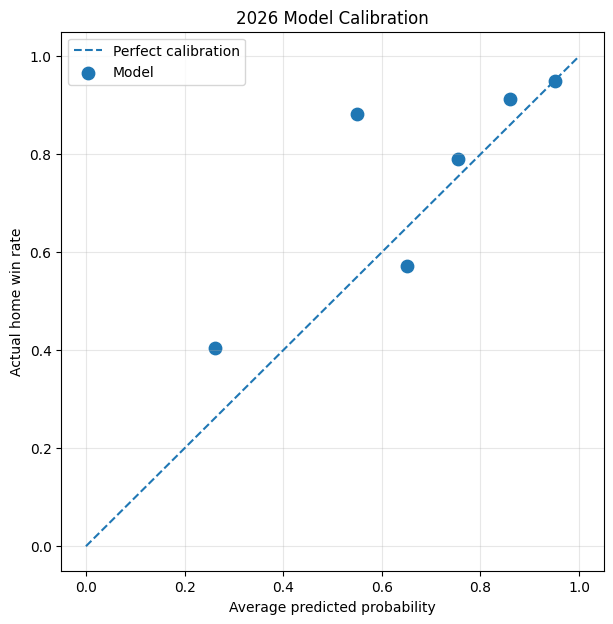

In [150]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Perfect calibration'
)

plt.scatter(
    calibration['average_predicted_probability'],
    calibration['actual_home_win_rate'],
    s=80,
    label='Model'
)

plt.xlabel('Average predicted probability')
plt.ylabel('Actual home win rate')
plt.title('2026 Model Calibration')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [151]:
coefficients = pd.DataFrame({
    'feature': features,
    'coefficient': model.coef_[0]
})

coefficients = coefficients.sort_values(
    'coefficient',
    ascending=False
)

coefficients

,feature,coefficient
3,returning_difference,0.579798
2,recruiting_grade_difference,0.168947
4,home_field,0.154158
0,prior_diff_difference,0.044916
1,talent_difference,0.001231


In [152]:
from sklearn.preprocessing import StandardScaler

numeric_features = [
    'prior_diff_difference',
    'talent_difference',
    'recruiting_grade_difference',
    'returning_difference'
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

X_test_scaled[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

scaled_model = LogisticRegression(max_iter=1000)

scaled_model.fit(
    X_train_scaled,
    y_train
)

scaled_coefficients = pd.DataFrame({
    'feature': features,
    'coefficient': scaled_model.coef_[0]
})

scaled_coefficients = scaled_coefficients.sort_values(
    'coefficient',
    ascending=False
)

scaled_coefficients

,feature,coefficient
0,prior_diff_difference,0.870315
2,recruiting_grade_difference,0.432003
1,talent_difference,0.226976
4,home_field,0.216918
3,returning_difference,0.174766


In [153]:
game_features['home_field'] = (
    ~game_features['neutral_site'].fillna(False)
).astype(int)

game_features['home_field'].value_counts()

home_field
1    3814
0     102
Name: count, dtype: int64

In [154]:
model_data = game_features.dropna(
    subset=model_features
).copy()

train_data = model_data[
    model_data['season'] < 2026
].copy()

test_data = model_data[
    model_data['season'] == 2026
].copy()

X_train = train_data[features]
y_train = train_data['home_win']

X_test = test_data[features]
y_test = test_data['home_win']

model = LogisticRegression(max_iter=1000)

model.fit(
    X_train,
    y_train
)

test_data['home_win_probability'] = model.predict_proba(
    X_test
)[:, 1]

test_data['predicted_home_win'] = (
    test_data['home_win_probability'] >= 0.5
).astype(int)

In [155]:
accuracy = accuracy_score(
    y_test,
    test_data['predicted_home_win']
)

logloss = log_loss(
    y_test,
    test_data['home_win_probability']
)

print(f"Test accuracy: {accuracy:.4f}")
print(f"Test log loss: {logloss:.4f}")

Test accuracy: 0.7857
Test log loss: 0.4743


In [157]:
import numpy as np

In [158]:
baseline_prob = y_train.mean()

baseline_accuracy = accuracy_score(
    y_test,
    np.ones(len(y_test))
)

baseline_logloss = log_loss(
    y_test,
    np.full(len(y_test), baseline_prob)
)

print(f"Baseline home-win probability: {baseline_prob:.4f}")
print(f"Baseline accuracy: {baseline_accuracy:.4f}")
print(f"Baseline log loss: {baseline_logloss:.4f}")

Baseline home-win probability: 0.5811
Baseline accuracy: 0.7338
Baseline log loss: 0.6300


In [159]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

feature_sets = {
    'All features': [
        'prior_diff_difference',
        'talent_difference',
        'recruiting_grade_difference',
        'returning_difference',
        'home_field'
    ],
    'Without prior performance': [
        'talent_difference',
        'recruiting_grade_difference',
        'returning_difference',
        'home_field'
    ],
    'Without talent': [
        'prior_diff_difference',
        'recruiting_grade_difference',
        'returning_difference',
        'home_field'
    ],
    'Without recruiting': [
        'prior_diff_difference',
        'talent_difference',
        'returning_difference',
        'home_field'
    ],
    'Without returning production': [
        'prior_diff_difference',
        'talent_difference',
        'recruiting_grade_difference',
        'home_field'
    ],
    'Without home field': [
        'prior_diff_difference',
        'talent_difference',
        'recruiting_grade_difference',
        'returning_difference'
    ]
}

results = []

for name, feature_set in feature_sets.items():
    temp_model = LogisticRegression(max_iter=1000)

    temp_model.fit(
        train_data[feature_set],
        y_train
    )

    probabilities = temp_model.predict_proba(
        test_data[feature_set]
    )[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, predictions),
        'log_loss': log_loss(y_test, probabilities)
    })

feature_comparison = pd.DataFrame(results)

feature_comparison

,model,accuracy,log_loss
0,All features,0.785714,0.474265
1,Without prior performance,0.818182,0.451241
2,Without talent,0.779221,0.478282
3,Without recruiting,0.746753,0.497624
4,Without returning production,0.759740,0.479383
5,Without home field,0.785714,0.479175


In [160]:
best_features = feature_sets['Without prior performance']

best_model = LogisticRegression(max_iter=1000)

best_model.fit(
    train_data[best_features],
    y_train
)

test_data['best_probability'] = best_model.predict_proba(
    test_data[best_features]
)[:, 1]

test_data['best_prediction'] = (
    test_data['best_probability'] >= 0.5
).astype(int)

best_calibration = (
    test_data.assign(
        probability_bin=pd.cut(
            test_data['best_probability'],
            bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
            include_lowest=True
        )
    )
    .groupby('probability_bin', observed=True)
    .agg(
        games=('home_win', 'count'),
        average_predicted_probability=('best_probability', 'mean'),
        actual_home_win_rate=('home_win', 'mean')
    )
    .reset_index()
)

best_calibration

,probability_bin,games,average_predicted_probability,actual_home_win_rate
0,"(-0.001, 0.5]",29,0.330357,0.275862
1,"(0.5, 0.6]",27,0.558185,0.703704
2,"(0.6, 0.7]",31,0.645446,0.709677
3,"(0.7, 0.8]",22,0.757584,0.954545
4,"(0.8, 0.9]",23,0.851866,0.913043
5,"(0.9, 1.0]",22,0.943053,1.000000


In [161]:
validation_features = [
    'talent_difference',
    'recruiting_grade_difference',
    'returning_difference',
    'home_field'
]

validation_results = []

for test_season in range(2022, 2027):
    
    train = model_data[
        model_data['season'] < test_season
    ].copy()
    
    test = model_data[
        model_data['season'] == test_season
    ].copy()
    
    validation_model = LogisticRegression(max_iter=1000)
    
    validation_model.fit(
        train[validation_features],
        train['home_win']
    )
    
    probabilities = validation_model.predict_proba(
        test[validation_features]
    )[:, 1]
    
    predictions = (
        probabilities >= 0.5
    ).astype(int)
    
    validation_results.append({
        'test_season': test_season,
        'games': len(test),
        'accuracy': accuracy_score(
            test['home_win'],
            predictions
        ),
        'log_loss': log_loss(
            test['home_win'],
            probabilities
        )
    })

validation_results = pd.DataFrame(
    validation_results
)

validation_results

,test_season,games,accuracy,log_loss
0,2022,720,0.641667,0.629209
1,2023,742,0.665768,0.582637
2,2024,746,0.620643,0.617560
3,2025,752,0.652926,0.617615
4,2026,154,0.818182,0.451241


In [162]:
original_features = [
    'prior_diff_difference',
    'talent_difference',
    'recruiting_grade_difference',
    'returning_difference',
    'home_field'
]

original_validation_results = []

for test_season in range(2022, 2027):
    
    train = model_data[
        model_data['season'] < test_season
    ].copy()
    
    test = model_data[
        model_data['season'] == test_season
    ].copy()
    
    validation_model = LogisticRegression(max_iter=1000)
    
    validation_model.fit(
        train[original_features],
        train['home_win']
    )
    
    probabilities = validation_model.predict_proba(
        test[original_features]
    )[:, 1]
    
    predictions = (
        probabilities >= 0.5
    ).astype(int)
    
    original_validation_results.append({
        'test_season': test_season,
        'games': len(test),
        'accuracy': accuracy_score(
            test['home_win'],
            predictions
        ),
        'log_loss': log_loss(
            test['home_win'],
            probabilities
        )
    })

original_validation_results = pd.DataFrame(
    original_validation_results
)

original_validation_results

,test_season,games,accuracy,log_loss
0,2022,720,0.691667,0.592803
1,2023,742,0.738544,0.530297
2,2024,746,0.710456,0.549977
3,2025,752,0.722074,0.557638
4,2026,154,0.785714,0.474265


In [163]:
comparison = original_validation_results.merge(
    validation_results,
    on=['test_season', 'games'],
    suffixes=('_original', '_without_prior')
)

comparison

,test_season,games,accuracy_original,log_loss_original,accuracy_without_prior,log_loss_without_prior
0,2022,720,0.691667,0.592803,0.641667,0.629209
1,2023,742,0.738544,0.530297,0.665768,0.582637
2,2024,746,0.710456,0.549977,0.620643,0.617560
3,2025,752,0.722074,0.557638,0.652926,0.617615
4,2026,154,0.785714,0.474265,0.818182,0.451241


In [164]:
print(
    f"Average accuracy: "
    f"{original_validation_results['accuracy'].mean():.4f}"
)

print(
    f"Average log loss: "
    f"{original_validation_results['log_loss'].mean():.4f}"
)

Average accuracy: 0.7297
Average log loss: 0.5410


In [165]:
home_scoring = fbs_games[
    ['season', 'start_date', 'home_id', 'home_points', 'away_points']
].copy()

home_scoring = home_scoring.rename(columns={
    'home_id': 'team_id',
    'home_points': 'points_for',
    'away_points': 'points_against'
})

away_scoring = fbs_games[
    ['season', 'start_date', 'away_id', 'away_points', 'home_points']
].copy()

away_scoring = away_scoring.rename(columns={
    'away_id': 'team_id',
    'away_points': 'points_for',
    'home_points': 'points_against'
})

team_scoring = pd.concat(
    [home_scoring, away_scoring],
    ignore_index=True
)

team_scoring = team_scoring.sort_values(
    ['team_id', 'start_date']
).reset_index(drop=True)

team_scoring.head()

,season,start_date,team_id,points_for,points_against
0,2021,2021-09-04 23:00:00+00:00,2,60.0,10.0
1,2021,2021-09-18 23:30:00+00:00,2,20.0,28.0
2,2021,2021-09-25 20:00:00+00:00,2,34.0,24.0
3,2021,2021-10-03 01:00:00+00:00,2,24.0,19.0
4,2021,2021-10-09 19:30:00+00:00,2,10.0,34.0


In [166]:
team_scoring['prior_points_for'] = (
    team_scoring
    .groupby(['team_id', 'season'])['points_for']
    .transform(
        lambda x: x.shift().expanding().mean()
    )
)

team_scoring['prior_points_against'] = (
    team_scoring
    .groupby(['team_id', 'season'])['points_against']
    .transform(
        lambda x: x.shift().expanding().mean()
    )
)

team_scoring[
    [
        'season',
        'team_id',
        'start_date',
        'points_for',
        'points_against',
        'prior_points_for',
        'prior_points_against'
    ]
].head(10)

,season,team_id,start_date,points_for,points_against,prior_points_for,prior_points_against
0,2021,2,2021-09-04 23:00:00+00:00,60.0,10.0,NaN,NaN
1,2021,2,2021-09-18 23:30:00+00:00,20.0,28.0,60.000000,10.000000
2,2021,2,2021-09-25 20:00:00+00:00,34.0,24.0,40.000000,19.000000
3,2021,2,2021-10-03 01:00:00+00:00,24.0,19.0,38.000000,20.666667
4,2021,2,2021-10-09 19:30:00+00:00,10.0,34.0,34.500000,20.250000
5,2021,2,2021-10-16 16:00:00+00:00,38.0,23.0,29.600000,23.000000
6,2021,2,2021-10-30 23:00:00+00:00,31.0,20.0,31.000000,23.000000
7,2021,2,2021-11-06 19:30:00+00:00,3.0,20.0,31.000000,22.571429
8,2021,2,2021-11-13 17:00:00+00:00,34.0,43.0,27.500000,22.250000
9,2021,2,2021-11-21 00:00:00+00:00,17.0,21.0,28.222222,24.555556


In [168]:
team_scoring['team_id'] = team_scoring['team_id'].astype(str)

In [169]:
home_scoring_features = team_scoring[
    [
        'season',
        'team_id',
        'start_date',
        'prior_points_for',
        'prior_points_against'
    ]
].rename(columns={
    'team_id': 'home_id',
    'prior_points_for': 'home_prior_points_for',
    'prior_points_against': 'home_prior_points_against'
})

away_scoring_features = team_scoring[
    [
        'season',
        'team_id',
        'start_date',
        'prior_points_for',
        'prior_points_against'
    ]
].rename(columns={
    'team_id': 'away_id',
    'prior_points_for': 'away_prior_points_for',
    'prior_points_against': 'away_prior_points_against'
})

game_features = game_features.merge(
    home_scoring_features,
    on=['season', 'home_id', 'start_date'],
    how='left'
)

game_features = game_features.merge(
    away_scoring_features,
    on=['season', 'away_id', 'start_date'],
    how='left'
)

game_features['offense_difference'] = (
    game_features['home_prior_points_for']
    - game_features['away_prior_points_for']
)

game_features['defense_difference'] = (
    game_features['away_prior_points_against']
    - game_features['home_prior_points_against']
)

game_features[
    [
        'home_team',
        'away_team',
        'offense_difference',
        'defense_difference'
    ]
].tail(10)

,home_team,away_team,offense_difference,defense_difference
3906,Northwestern,Colorado,NaN,NaN
3907,Tennessee,Kennesaw State,28.0,7.0
3908,Texas,UTSA,10.5,11.0
3909,TCU,Arkansas State,-14.0,27.0
3910,Louisiana,UAB,5.5,-18.0
3911,San Diego State,James Madison,-10.0,-15.0
3912,Arizona,Northern Illinois,17.0,12.0
3913,Sacramento State,North Dakota State,-25.5,-19.0
3914,San José State,Fresno State,2.0,-10.5
3915,UCLA,Purdue,0.5,21.0


In [170]:
new_features = [
    'offense_difference',
    'defense_difference'
]

print(
    game_features[new_features]
    .isna()
    .sum()
)

print(
    "Games missing either feature:",
    game_features[new_features].isna().any(axis=1).sum()
)

offense_difference    503
defense_difference    503
dtype: int64
Games missing either feature: 503


In [171]:
id="v7k2qa"
expanded_features = [
    'prior_diff_difference',
    'talent_difference',
    'recruiting_grade_difference',
    'returning_difference',
    'home_field',
    'offense_difference',
    'defense_difference'
]

expanded_validation_results = []

for test_season in range(2022, 2027):
    train = game_features[
        (game_features['season'] < test_season)
    ].dropna(subset=expanded_features).copy()

    test = game_features[
        (game_features['season'] == test_season)
    ].dropna(subset=expanded_features).copy()

    validation_model = LogisticRegression(max_iter=1000)

    validation_model.fit(
        train[expanded_features],
        train['home_win']
    )

    probabilities = validation_model.predict_proba(
        test[expanded_features]
    )[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    expanded_validation_results.append({
        'test_season': test_season,
        'games': len(test),
        'accuracy': accuracy_score(
            test['home_win'],
            predictions
        ),
        'log_loss': log_loss(
            test['home_win'],
            probabilities
        )
    })

expanded_validation_results = pd.DataFrame(
    expanded_validation_results
)

expanded_validation_results

,test_season,games,accuracy,log_loss
0,2022,639,0.687011,0.599140
1,2023,662,0.732628,0.539998
2,2024,665,0.711278,0.553535
3,2025,670,0.713433,0.562570
4,2026,69,0.666667,0.606007


In [172]:
offense_features = [
    'prior_diff_difference',
    'talent_difference',
    'recruiting_grade_difference',
    'returning_difference',
    'home_field',
    'offense_difference'
]

defense_features = [
    'prior_diff_difference',
    'talent_difference',
    'recruiting_grade_difference',
    'returning_difference',
    'home_field',
    'defense_difference'
]

offense_validation_results = []
defense_validation_results = []

for test_season in range(2022, 2027):

    # ----- Offense model -----
    train = game_features[
        game_features['season'] < test_season
    ].dropna(subset=offense_features)

    test = game_features[
        game_features['season'] == test_season
    ].dropna(subset=offense_features)

    model_offense = LogisticRegression(max_iter=1000)
    model_offense.fit(
        train[offense_features],
        train['home_win']
    )

    probabilities = model_offense.predict_proba(
        test[offense_features]
    )[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    offense_validation_results.append({
        'test_season': test_season,
        'games': len(test),
        'accuracy': accuracy_score(
            test['home_win'],
            predictions
        ),
        'log_loss': log_loss(
            test['home_win'],
            probabilities
        )
    })

    # ----- Defense model -----
    train = game_features[
        game_features['season'] < test_season
    ].dropna(subset=defense_features)

    test = game_features[
        game_features['season'] == test_season
    ].dropna(subset=defense_features)

    model_defense = LogisticRegression(max_iter=1000)
    model_defense.fit(
        train[defense_features],
        train['home_win']
    )

    probabilities = model_defense.predict_proba(
        test[defense_features]
    )[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    defense_validation_results.append({
        'test_season': test_season,
        'games': len(test),
        'accuracy': accuracy_score(
            test['home_win'],
            predictions
        ),
        'log_loss': log_loss(
            test['home_win'],
            probabilities
        )
    })

offense_validation_results = pd.DataFrame(
    offense_validation_results
)

defense_validation_results = pd.DataFrame(
    defense_validation_results
)

print("OFFENSE MODEL")
display(offense_validation_results)

print("DEFENSE MODEL")
display(defense_validation_results)

OFFENSE MODEL


,test_season,games,accuracy,log_loss
0,2022,639,0.687011,0.599137
1,2023,662,0.732628,0.539998
2,2024,665,0.711278,0.553535
3,2025,670,0.713433,0.562571
4,2026,69,0.666667,0.606006


DEFENSE MODEL


,test_season,games,accuracy,log_loss
0,2022,639,0.685446,0.599202
1,2023,662,0.732628,0.539998
2,2024,665,0.711278,0.553536
3,2025,670,0.713433,0.562571
4,2026,69,0.666667,0.606009


In [173]:
from pathlib import Path

box_files = sorted(
    Path("../data/raw").glob("*team_box*.csv")
)

for file in box_files:
    print(file.name)

team_box_2021.csv
team_box_2022.csv
team_box_2023.csv
team_box_2024.csv
team_box_2025.csv
team_box_2026.csv


In [174]:
for file in box_files:
    temp = pd.read_csv(file)

    print(f"\n{file.name}")
    print(temp.columns.tolist())


team_box_2021.csv
['firstDowns', 'thirdDownEff', 'fourthDownEff', 'totalYards', 'netPassingYards', 'completionAttempts', 'yardsPerPass', 'rushingYards', 'rushingAttempts', 'yardsPerRushAttempt', 'totalPenaltiesYards', 'turnovers', 'fumblesLost', 'interceptions', 'possessionTime', 'team_id', 'team_abbreviation', 'team_name', 'home_away', 'game_id', 'season']

team_box_2022.csv
['firstDowns', 'thirdDownEff', 'fourthDownEff', 'totalYards', 'netPassingYards', 'completionAttempts', 'yardsPerPass', 'rushingYards', 'rushingAttempts', 'yardsPerRushAttempt', 'totalPenaltiesYards', 'turnovers', 'fumblesLost', 'interceptions', 'possessionTime', 'team_id', 'team_abbreviation', 'team_name', 'home_away', 'game_id', 'season']

team_box_2023.csv
['firstDowns', 'thirdDownEff', 'fourthDownEff', 'totalYards', 'netPassingYards', 'completionAttempts', 'yardsPerPass', 'rushingYards', 'rushingAttempts', 'yardsPerRushAttempt', 'totalPenaltiesYards', 'turnovers', 'fumblesLost', 'interceptions', 'possessionTim

In [175]:
box_data = []

for file in box_files:
    temp = pd.read_csv(file)

    temp = temp[
        [
            'game_id',
            'season',
            'team_id',
            'team_name',
            'home_away',
            'totalYards',
            'netPassingYards',
            'rushingYards'
        ]
    ].copy()

    box_data.append(temp)

all_team_box = pd.concat(
    box_data,
    ignore_index=True
)

all_team_box['team_id'] = (
    all_team_box['team_id']
    .astype(str)
)

print("Rows:", len(all_team_box))
print("Columns:", all_team_box.columns.tolist())

all_team_box.head()

Rows: 9788
Columns: ['game_id', 'season', 'team_id', 'team_name', 'home_away', 'totalYards', 'netPassingYards', 'rushingYards']


,game_id,season,team_id,team_name,home_away,totalYards,netPassingYards,rushingYards
0,401282714,2021,158,Nebraska Cornhuskers,away,392.0,232.0,160.0
1,401282714,2021,356,Illinois Fighting Illini,home,326.0,159.0,167.0
2,401286187,2021,41,UConn Huskies,away,107.0,72.0,35.0
3,401286187,2021,278,Fresno State Bulldogs,home,538.0,382.0,156.0
4,401309833,2021,62,Hawai'i Rainbow Warriors,away,269.0,243.0,26.0


In [176]:
all_team_box = all_team_box.merge(
    fbs_games[
        ['game_id', 'start_date']
    ].drop_duplicates('game_id'),
    on='game_id',
    how='left'
)

all_team_box = all_team_box.sort_values(
    ['team_id', 'start_date']
).reset_index(drop=True)

all_team_box[
    [
        'team_name',
        'season',
        'start_date',
        'totalYards',
        'netPassingYards',
        'rushingYards'
    ]
].head(10)

,team_name,season,start_date,totalYards,netPassingYards,rushingYards
0,Boston College Eagles,2021,2021-09-11 19:30:00+00:00,475.0,221.0,254.0
1,Boston College Eagles,2021,2021-09-18 16:00:00+00:00,238.0,59.0,179.0
2,Boston College Eagles,2021,2021-09-25 16:00:00+00:00,450.0,175.0,275.0
3,Boston College Eagles,2021,2021-10-02 23:30:00+00:00,357.0,311.0,46.0
4,Boston College Eagles,2021,2021-10-16 23:30:00+00:00,291.0,194.0,97.0
5,Boston College Eagles,2021,2021-10-23 20:00:00+00:00,266.0,141.0,125.0
6,Boston College Eagles,2021,2021-10-30 19:30:00+00:00,251.0,180.0,71.0
7,Boston College Eagles,2021,2021-11-05 23:30:00+00:00,346.0,112.0,234.0
8,Boston College Eagles,2021,2021-11-13 20:30:00+00:00,505.0,310.0,195.0
9,Boston College Eagles,2021,2021-11-20 17:00:00+00:00,318.0,148.0,170.0


In [177]:
all_team_box['prior_total_yards'] = (
    all_team_box
    .groupby(['team_id', 'season'])['totalYards']
    .transform(
        lambda x: x.shift().expanding().mean()
    )
)

all_team_box['prior_passing_yards'] = (
    all_team_box
    .groupby(['team_id', 'season'])['netPassingYards']
    .transform(
        lambda x: x.shift().expanding().mean()
    )
)

all_team_box['prior_rushing_yards'] = (
    all_team_box
    .groupby(['team_id', 'season'])['rushingYards']
    .transform(
        lambda x: x.shift().expanding().mean()
    )
)

all_team_box[
    [
        'team_name',
        'season',
        'totalYards',
        'prior_total_yards',
        'netPassingYards',
        'prior_passing_yards',
        'rushingYards',
        'prior_rushing_yards'
    ]
].head(10)

,team_name,season,totalYards,prior_total_yards,netPassingYards,prior_passing_yards,rushingYards,prior_rushing_yards
0,Boston College Eagles,2021,475.0,NaN,221.0,NaN,254.0,NaN
1,Boston College Eagles,2021,238.0,475.000000,59.0,221.000000,179.0,254.000000
2,Boston College Eagles,2021,450.0,356.500000,175.0,140.000000,275.0,216.500000
3,Boston College Eagles,2021,357.0,387.666667,311.0,151.666667,46.0,236.000000
4,Boston College Eagles,2021,291.0,380.000000,194.0,191.500000,97.0,188.500000
5,Boston College Eagles,2021,266.0,362.200000,141.0,192.000000,125.0,170.200000
6,Boston College Eagles,2021,251.0,346.166667,180.0,183.500000,71.0,162.666667
7,Boston College Eagles,2021,346.0,332.571429,112.0,183.000000,234.0,149.571429
8,Boston College Eagles,2021,505.0,334.250000,310.0,174.125000,195.0,160.125000
9,Boston College Eagles,2021,318.0,353.222222,148.0,189.222222,170.0,164.000000


In [178]:
home_box_features = all_team_box[
    [
        'game_id',
        'team_id',
        'prior_total_yards',
        'prior_passing_yards',
        'prior_rushing_yards'
    ]
].rename(columns={
    'team_id': 'home_id',
    'prior_total_yards': 'home_prior_total_yards',
    'prior_passing_yards': 'home_prior_passing_yards',
    'prior_rushing_yards': 'home_prior_rushing_yards'
})

away_box_features = all_team_box[
    [
        'game_id',
        'team_id',
        'prior_total_yards',
        'prior_passing_yards',
        'prior_rushing_yards'
    ]
].rename(columns={
    'team_id': 'away_id',
    'prior_total_yards': 'away_prior_total_yards',
    'prior_passing_yards': 'away_prior_passing_yards',
    'prior_rushing_yards': 'away_prior_rushing_yards'
})

# Make sure IDs have the same type
game_features['home_id'] = game_features['home_id'].astype(str)
game_features['away_id'] = game_features['away_id'].astype(str)

# Merge home-team statistics
game_features = game_features.merge(
    home_box_features,
    on=['game_id', 'home_id'],
    how='left'
)

# Merge away-team statistics
game_features = game_features.merge(
    away_box_features,
    on=['game_id', 'away_id'],
    how='left'
)

# Create home-vs-away differences
game_features['total_yards_difference'] = (
    game_features['home_prior_total_yards']
    - game_features['away_prior_total_yards']
)

game_features['passing_yards_difference'] = (
    game_features['home_prior_passing_yards']
    - game_features['away_prior_passing_yards']
)

game_features['rushing_yards_difference'] = (
    game_features['home_prior_rushing_yards']
    - game_features['away_prior_rushing_yards']
)

game_features[
    [
        'home_team',
        'away_team',
        'total_yards_difference',
        'passing_yards_difference',
        'rushing_yards_difference'
    ]
].tail(10)

,home_team,away_team,total_yards_difference,passing_yards_difference,rushing_yards_difference
3906,Northwestern,Colorado,NaN,NaN,NaN
3907,Tennessee,Kennesaw State,115.0,-112.0,227.0
3908,Texas,UTSA,28.0,19.5,8.5
3909,TCU,Arkansas State,-153.0,-150.0,-3.0
3910,Louisiana,UAB,-39.0,45.0,-84.0
3911,San Diego State,James Madison,-102.0,-73.0,-29.0
3912,Arizona,Northern Illinois,207.0,117.0,90.0
3913,Sacramento State,North Dakota State,-108.5,-10.0,-97.0
3914,San José State,Fresno State,65.5,62.0,3.5
3915,UCLA,Purdue,-42.0,-161.5,119.5


In [179]:
yard_features = [
    'total_yards_difference',
    'passing_yards_difference',
    'rushing_yards_difference'
]

print(
    game_features[yard_features]
    .isna()
    .sum()
)

print(
    "Games missing any yardage feature:",
    game_features[yard_features]
    .isna()
    .any(axis=1)
    .sum()
)

total_yards_difference      503
passing_yards_difference    503
rushing_yards_difference    503
dtype: int64
Games missing any yardage feature: 503


In [181]:
yard_feature_sets = {
    'Total yards': [
        'prior_diff_difference',
        'talent_difference',
        'recruiting_grade_difference',
        'returning_difference',
        'home_field',
        'total_yards_difference'
    ],
    'Passing yards': [
        'prior_diff_difference',
        'talent_difference',
        'recruiting_grade_difference',
        'returning_difference',
        'home_field',
        'passing_yards_difference'
    ],
    'Rushing yards': [
        'prior_diff_difference',
        'talent_difference',
        'recruiting_grade_difference',
        'returning_difference',
        'home_field',
        'rushing_yards_difference'
    ],
    'All yardage': [
        'prior_diff_difference',
        'talent_difference',
        'recruiting_grade_difference',
        'returning_difference',
        'home_field',
        'total_yards_difference',
        'passing_yards_difference',
        'rushing_yards_difference'
    ]
}

yard_validation_results = []

for name, feature_list in yard_feature_sets.items():

    for test_season in range(2022, 2027):

        train = game_features[
            game_features['season'] < test_season
        ].dropna(subset=feature_list)

        test = game_features[
            game_features['season'] == test_season
        ].dropna(subset=feature_list)

        validation_model = LogisticRegression(max_iter=1000)

        validation_model.fit(
            train[feature_list],
            train['home_win']
        )

        probabilities = validation_model.predict_proba(
            test[feature_list]
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        yard_validation_results.append({
            'feature_set': name,
            'test_season': test_season,
            'games': len(test),
            'accuracy': accuracy_score(
                test['home_win'],
                predictions
            ),
            'log_loss': log_loss(
                test['home_win'],
                probabilities
            )
        })

yard_validation_results = pd.DataFrame(
    yard_validation_results
)

yard_validation_results

,feature_set,test_season,games,accuracy,log_loss
0,Total yards,2022,639,0.683881,0.599870
1,Total yards,2023,662,0.738671,0.538352
2,Total yards,2024,665,0.702256,0.553857
3,Total yards,2025,670,0.710448,0.563622
4,Total yards,2026,69,0.681159,0.610588
5,Passing yards,2022,639,0.691706,0.601245
6,Passing yards,2023,662,0.732628,0.539978
7,Passing yards,2024,665,0.709774,0.554642
8,Passing yards,2025,670,0.717910,0.562378
9,Passing yards,2026,69,0.666667,0.606561


In [182]:
c_values = [0.01, 0.1, 1, 10, 100]

regularization_results = []

for c in c_values:

    for test_season in range(2022, 2027):

        train = model_data[
            model_data['season'] < test_season
        ].copy()

        test = model_data[
            model_data['season'] == test_season
        ].copy()

        model_c = LogisticRegression(
            C=c,
            max_iter=1000
        )

        model_c.fit(
            train[original_features],
            train['home_win']
        )

        probabilities = model_c.predict_proba(
            test[original_features]
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        regularization_results.append({
            'C': c,
            'test_season': test_season,
            'accuracy': accuracy_score(
                test['home_win'],
                predictions
            ),
            'log_loss': log_loss(
                test['home_win'],
                probabilities
            )
        })

regularization_results = pd.DataFrame(
    regularization_results
)

regularization_results

,C,test_season,accuracy,log_loss
0,0.01,2022,0.687500,0.592659
1,0.01,2023,0.742588,0.535815
2,0.01,2024,0.711796,0.551594
3,0.01,2025,0.716755,0.557346
4,0.01,2026,0.772727,0.481910
5,0.10,2022,0.688889,0.593126
6,0.10,2023,0.738544,0.531911
7,0.10,2024,0.710456,0.549942
8,0.10,2025,0.718085,0.557263
9,0.10,2026,0.785714,0.476293


In [183]:
from sklearn.ensemble import RandomForestClassifier

rf_results = []

for test_season in range(2022, 2027):

    train = model_data[
        model_data['season'] < test_season
    ].copy()

    test = model_data[
        model_data['season'] == test_season
    ].copy()

    rf_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=10,
        random_state=42
    )

    rf_model.fit(
        train[original_features],
        train['home_win']
    )

    probabilities = rf_model.predict_proba(
        test[original_features]
    )[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    rf_results.append({
        'test_season': test_season,
        'games': len(test),
        'accuracy': accuracy_score(
            test['home_win'],
            predictions
        ),
        'log_loss': log_loss(
            test['home_win'],
            probabilities
        )
    })

rf_results = pd.DataFrame(rf_results)

rf_results

,test_season,games,accuracy,log_loss
0,2022,720,0.700000,0.588256
1,2023,742,0.727763,0.539452
2,2024,746,0.714477,0.559214
3,2025,752,0.718085,0.564455
4,2026,154,0.753247,0.469362


In [184]:
rf_settings = [
    (3, 5),
    (5, 5),
    (5, 10),
    (8, 5),
    (8, 10),
    (10, 5),
    (10, 10)
]

rf_tuning_results = []

for max_depth, min_leaf in rf_settings:

    season_results = []

    for test_season in range(2022, 2027):

        train = model_data[
            model_data['season'] < test_season
        ].copy()

        test = model_data[
            model_data['season'] == test_season
        ].copy()

        rf_model = RandomForestClassifier(
            n_estimators=300,
            max_depth=max_depth,
            min_samples_leaf=min_leaf,
            random_state=42
        )

        rf_model.fit(
            train[original_features],
            train['home_win']
        )

        probabilities = rf_model.predict_proba(
            test[original_features]
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        season_results.append({
            'accuracy': accuracy_score(
                test['home_win'],
                predictions
            ),
            'log_loss': log_loss(
                test['home_win'],
                probabilities
            )
        })

    rf_tuning_results.append({
        'max_depth': max_depth,
        'min_samples_leaf': min_leaf,
        'average_accuracy': np.mean([
            x['accuracy'] for x in season_results
        ]),
        'average_log_loss': np.mean([
            x['log_loss'] for x in season_results
        ])
    })

rf_tuning_results = pd.DataFrame(
    rf_tuning_results
).sort_values('average_log_loss')

rf_tuning_results

,max_depth,min_samples_leaf,average_accuracy,average_log_loss
1,5,5,0.722430,0.544072
2,5,10,0.722714,0.544148
4,8,10,0.715856,0.549040
0,3,5,0.725336,0.549552
3,8,5,0.716722,0.550037
6,10,10,0.716437,0.551381
5,10,5,0.714293,0.553840


In [185]:
from sklearn.ensemble import GradientBoostingClassifier

gb_results = []

for test_season in range(2022, 2027):

    train = model_data[
        model_data['season'] < test_season
    ].copy()

    test = model_data[
        model_data['season'] == test_season
    ].copy()

    gb_model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )

    gb_model.fit(
        train[original_features],
        train['home_win']
    )

    probabilities = gb_model.predict_proba(
        test[original_features]
    )[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    gb_results.append({
        'test_season': test_season,
        'games': len(test),
        'accuracy': accuracy_score(
            test['home_win'],
            predictions
        ),
        'log_loss': log_loss(
            test['home_win'],
            probabilities
        )
    })

gb_results = pd.DataFrame(gb_results)

gb_results

,test_season,games,accuracy,log_loss
0,2022,720,0.680556,0.603789
1,2023,742,0.723720,0.542881
2,2024,746,0.711796,0.561985
3,2025,752,0.731383,0.559326
4,2026,154,0.759740,0.476679


In [186]:
print(
    f"Gradient Boosting average accuracy: "
    f"{gb_results['accuracy'].mean():.4f}"
)

print(
    f"Gradient Boosting average log loss: "
    f"{gb_results['log_loss'].mean():.4f}"
)


Gradient Boosting average accuracy: 0.7214
Gradient Boosting average log loss: 0.5489


In [187]:
# Ensure team IDs and seasons are in a consistent format
team_season['team_id'] = team_season['team_id'].astype(str)
season_avg_diff['team_id'] = season_avg_diff['team_id'].astype(str)

# Put each team's seasons in chronological order
season_avg_diff = season_avg_diff.sort_values(
    ['team_id', 'season']
).copy()

# Calculate each team's average point differential
# from the previous available season
season_avg_diff['previous_season_diff'] = (
    season_avg_diff
    .groupby('team_id')['season_avg_diff']
    .shift(1)
)

# Attach previous-season performance to the team-season data
team_season = team_season.merge(
    season_avg_diff[
        ['team_id', 'season', 'previous_season_diff']
    ],
    on=['team_id', 'season'],
    how='left'
)

# Inspect the result
team_season[
    [
        'season',
        'team',
        'talent_composite',
        'avg_grade',
        'overall_returning',
        'previous_season_diff'
    ]
].head(15)

,season,team,talent_composite,avg_grade,overall_returning,previous_season_diff
0,2021,Georgia Bulldogs,1291.950448,92.253135,0.945998,NaN
1,2021,Alabama Crimson Tide,1266.873313,91.381066,0.381111,NaN
2,2021,Ohio State Buckeyes,1236.809675,92.284770,0.420317,NaN
3,2021,Clemson Tigers,1222.761076,92.976470,0.311700,NaN
4,2021,Michigan Wolverines,1138.647092,88.724895,0.521590,NaN
5,2021,LSU Tigers,1115.737782,90.634592,0.670144,NaN
6,2021,Penn State Nittany Lions,1099.054430,89.124868,0.826529,NaN
7,2021,Texas A&M Aggies,1079.382778,88.639965,0.609843,NaN
8,2021,Texas Longhorns,1064.112519,88.570457,0.416942,NaN
9,2021,Oregon Ducks,1058.609290,88.652201,0.542876,NaN


In [188]:
# Create a team-season performance measure
# from the games we already have

team_performance = team_results.groupby(
    ['team_id', 'season']
).agg(
    avg_point_diff=('point_diff', 'mean'),
    games=('point_diff', 'count')
).reset_index()

team_performance['team_id'] = (
    team_performance['team_id'].astype(str)
)

team_performance.head()

,team_id,season,avg_point_diff,games
0,2,2021,2.454545,11
1,2,2022,-7.545455,11
2,2,2023,2.909091,11
3,2,2024,0.636364,11
4,2,2025,2.545455,11


In [189]:
# Calculate each team's win percentage for each season

team_results['win'] = (
    team_results['point_diff'] > 0
).astype(int)

team_win_pct = (
    team_results
    .groupby(['team_id', 'season'])
    .agg(
        win_pct=('win', 'mean')
    )
    .reset_index()
)

team_win_pct['team_id'] = (
    team_win_pct['team_id'].astype(str)
)

# Add win percentage to our performance table

team_performance = team_performance.merge(
    team_win_pct,
    on=['team_id', 'season'],
    how='left'
)

team_performance.head(15)

,team_id,season,avg_point_diff,games,win_pct
0,2,2021,2.454545,11,0.454545
1,2,2022,-7.545455,11,0.363636
2,2,2023,2.909091,11,0.454545
3,2,2024,0.636364,11,0.363636
4,2,2025,2.545455,11,0.363636
5,2,2026,10.333333,3,0.666667
6,5,2021,6.583333,12,0.666667
7,5,2022,2.454545,11,0.454545
8,5,2023,-10.272727,11,0.272727
9,5,2024,-12.272727,11,0.181818


In [190]:
# Put seasons in chronological order
team_performance = team_performance.sort_values(
    ['team_id', 'season']
).copy()

# Previous-season performance
team_performance['previous_avg_point_diff'] = (
    team_performance
    .groupby('team_id')['avg_point_diff']
    .shift(1)
)

team_performance['previous_win_pct'] = (
    team_performance
    .groupby('team_id')['win_pct']
    .shift(1)
)

team_performance.head(15)

,team_id,season,avg_point_diff,games,win_pct,previous_avg_point_diff,previous_win_pct
197,103,2021,-1.909091,11,0.454545,NaN,NaN
198,103,2022,-15.636364,11,0.181818,-1.909091,0.454545
199,103,2023,-5.181818,11,0.454545,-15.636364,0.181818
200,103,2024,0.545455,11,0.545455,-5.181818,0.454545
201,103,2025,-13.090909,11,0.090909,0.545455,0.545455
202,103,2026,-6.000000,2,0.500000,-13.090909,0.090909
203,113,2021,-28.300000,10,0.100000,NaN,NaN
204,113,2022,-21.818182,11,0.000000,-28.300000,0.100000
205,113,2023,-16.909091,11,0.181818,-21.818182,0.000000
206,113,2024,-18.800000,10,0.000000,-16.909091,0.181818


In [191]:
# Add previous-season performance to our team-season data

team_season = team_season.merge(
    team_performance[
        [
            'team_id',
            'season',
            'previous_avg_point_diff',
            'previous_win_pct'
        ]
    ],
    on=['team_id', 'season'],
    how='left'
)

team_season[
    [
        'season',
        'team',
        'talent_composite',
        'avg_grade',
        'overall_returning',
        'previous_avg_point_diff',
        'previous_win_pct'
    ]
].head(20)

,season,team,talent_composite,avg_grade,overall_returning,previous_avg_point_diff,previous_win_pct
0,2021,Georgia Bulldogs,1291.950448,92.253135,0.945998,NaN,NaN
1,2021,Alabama Crimson Tide,1266.873313,91.381066,0.381111,NaN,NaN
2,2021,Ohio State Buckeyes,1236.809675,92.284770,0.420317,NaN,NaN
3,2021,Clemson Tigers,1222.761076,92.976470,0.311700,NaN,NaN
4,2021,Michigan Wolverines,1138.647092,88.724895,0.521590,NaN,NaN
5,2021,LSU Tigers,1115.737782,90.634592,0.670144,NaN,NaN
6,2021,Penn State Nittany Lions,1099.054430,89.124868,0.826529,NaN,NaN
7,2021,Texas A&M Aggies,1079.382778,88.639965,0.609843,NaN,NaN
8,2021,Texas Longhorns,1064.112519,88.570457,0.416942,NaN,NaN
9,2021,Oregon Ducks,1058.609290,88.652201,0.542876,NaN,NaN


In [192]:
strength_features = [
    'talent_composite',
    'avg_grade',
    'overall_returning',
    'previous_avg_point_diff',
    'previous_win_pct'
]

strength_data = team_season.dropna(
    subset=strength_features + ['avg_point_diff']
).copy()

print("Usable team-seasons:", len(strength_data))
print("Seasons:")
print(strength_data['season'].value_counts().sort_index())

KeyError: ['avg_point_diff']

In [193]:
strength_features = [
    'talent_composite',
    'avg_grade',
    'overall_returning',
    'previous_avg_point_diff',
    'previous_win_pct'
]

# Add the current-season performance that we want to predict
strength_data = team_season.merge(
    team_performance[
        ['team_id', 'season', 'avg_point_diff']
    ],
    on=['team_id', 'season'],
    how='left'
)

# Keep only rows with all required information
strength_data = strength_data.dropna(
    subset=strength_features + ['avg_point_diff']
).copy()

print("Usable team-seasons:", len(strength_data))
print("\nSeasons:")
print(
    strength_data['season']
    .value_counts()
    .sort_index()
)

Usable team-seasons: 677

Seasons:
season
2022    133
2023    136
2024    135
2025    136
2026    137
Name: count, dtype: int64


In [194]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

strength_features = [
    'talent_composite',
    'avg_grade',
    'overall_returning',
    'previous_avg_point_diff',
    'previous_win_pct'
]

# Train on 2022-2024
train_strength = strength_data[
    strength_data['season'] <= 2024
].copy()

# Test on 2025
test_strength = strength_data[
    strength_data['season'] == 2025
].copy()

X_train_strength = train_strength[strength_features]
y_train_strength = train_strength['avg_point_diff']

X_test_strength = test_strength[strength_features]
y_test_strength = test_strength['avg_point_diff']

strength_model = Ridge(alpha=1.0)

strength_model.fit(
    X_train_strength,
    y_train_strength
)

test_strength['predicted_strength'] = strength_model.predict(
    X_test_strength
)

mae = mean_absolute_error(
    y_test_strength,
    test_strength['predicted_strength']
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_strength,
        test_strength['predicted_strength']
    )
)

print("2025 MAE:", mae)
print("2025 RMSE:", rmse)

2025 MAE: 7.391623624874942
2025 RMSE: 9.369234490481567


In [196]:
results = []

for season in range(2023, 2027):

    train_strength = strength_data[
        strength_data['season'] < season
    ].copy()

    test_strength = strength_data[
        strength_data['season'] == season
    ].copy()

    X_train = train_strength[strength_features]
    y_train = train_strength['avg_point_diff']

    X_test = test_strength[strength_features]
    y_test = test_strength['avg_point_diff']

    model = Ridge(alpha=1.0)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        'season': season,
        'teams': len(test_strength),
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions))
    })

strength_results = pd.DataFrame(results)

strength_results


,season,teams,MAE,RMSE
0,2023,136,7.027881,9.536774
1,2024,135,7.585115,9.673908
2,2025,136,7.391624,9.369234
3,2026,137,12.459687,15.764100


In [198]:
team_performance[
    team_performance['season'] == 2026
][['team_id', 'season', 'games', 'avg_point_diff']].describe()

,season,games,avg_point_diff
count,138.0,138.000000,138.000000
mean,2026.0,2.275362,-0.501208
std,0.0,0.550622,18.947009
min,2026.0,1.000000,-56.500000
25%,2026.0,2.000000,-10.875000
50%,2026.0,2.000000,-0.500000
75%,2026.0,3.000000,11.500000
max,2026.0,4.000000,39.000000


In [199]:
team_performance[
    team_performance['season'] == 2026
][['team_id', 'games', 'avg_point_diff']].sort_values(
    'games'
).head(20)

,team_id,games,avg_point_diff
208,113,1,16.0
561,2005,1,-6.0
687,2426,1,-8.0
549,349,1,-4.0
160,77,1,34.0
238,142,2,13.5
268,153,2,-1.5
232,135,2,4.5
280,158,2,38.5
334,197,2,-3.0


In [200]:
strength_data[
    strength_data['season'] == 2026
][
    [
        'team',
        'talent_composite',
        'avg_grade',
        'overall_returning',
        'previous_avg_point_diff',
        'previous_win_pct'
    ]
].isna().sum()

team                       0
talent_composite           0
avg_grade                  0
overall_returning          0
previous_avg_point_diff    0
previous_win_pct           0
dtype: int64

In [201]:
strength_features = [
    'talent_composite',
    'avg_grade',
    'overall_returning',
    'previous_avg_point_diff',
    'previous_win_pct'
]

train_preseason = strength_data[
    strength_data['season'] < 2026
].copy()

preseason_2026 = strength_data[
    strength_data['season'] == 2026
].copy()

X_train = train_preseason[strength_features]
y_train = train_preseason['avg_point_diff']

X_2026 = preseason_2026[strength_features]

preseason_model = Ridge(alpha=1.0)
preseason_model.fit(X_train, y_train)

preseason_2026['preseason_strength'] = (
    preseason_model.predict(X_2026)
)

preseason_2026[
    ['team', 'preseason_strength']
].sort_values(
    'preseason_strength',
    ascending=False
).head(20)

,team,preseason_strength
1567,Notre Dame Fighting Irish,20.001163
1565,Oregon Ducks,19.206021
1566,Ohio State Buckeyes,18.844810
1562,Georgia Bulldogs,17.316300
1582,Texas Tech Red Raiders,16.401177
1571,Miami Hurricanes,15.092477
1569,USC Trojans,14.865876
1564,Texas Longhorns,13.944291
1563,Alabama Crimson Tide,13.669623
1568,Texas A&M Aggies,13.313615


In [202]:
strength_2026 = preseason_2026[
    ['team_id', 'preseason_strength']
].copy()

strength_2026['team_id'] = strength_2026['team_id'].astype(str)

game_strength = fbs_games[
    fbs_games['season'] == 2026
].copy()

game_strength['home_id'] = game_strength['home_id'].astype(str)
game_strength['away_id'] = game_strength['away_id'].astype(str)

game_strength = game_strength.merge(
    strength_2026.rename(columns={
        'team_id': 'home_id',
        'preseason_strength': 'home_preseason_strength'
    }),
    on='home_id',
    how='left'
)

game_strength = game_strength.merge(
    strength_2026.rename(columns={
        'team_id': 'away_id',
        'preseason_strength': 'away_preseason_strength'
    }),
    on='away_id',
    how='left'
)

game_strength['preseason_strength_difference'] = (
    game_strength['home_preseason_strength']
    - game_strength['away_preseason_strength']
)

game_strength['home_field'] = (
    ~game_strength['neutral_site'].fillna(False)
).astype(int)

game_strength[
    [
        'home_team',
        'away_team',
        'home_preseason_strength',
        'away_preseason_strength',
        'preseason_strength_difference',
        'home_field'
    ]
].head()

,home_team,away_team,home_preseason_strength,away_preseason_strength,preseason_strength_difference,home_field
0,TCU,North Carolina,3.369590,-0.887953,4.257544,0
1,USC,San José State,14.865876,-8.444221,23.310097,1
2,Virginia,NC State,0.939364,0.940588,-0.001225,1
3,North Dakota State,Jacksonville State,5.040426,-1.933430,6.973856,1
4,Eastern Michigan,Sacramento State,-2.323566,-4.486281,2.162715,1


In [203]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

strength_model_data = game_strength.dropna(
    subset=[
        'preseason_strength_difference',
        'home_field'
    ]
).copy()

X_strength = strength_model_data[
    [
        'preseason_strength_difference',
        'home_field'
    ]
]

y_strength = strength_model_data['home_win']

strength_logistic = LogisticRegression()
strength_logistic.fit(X_strength, y_strength)

strength_model_data['home_win_probability'] = (
    strength_logistic.predict_proba(X_strength)[:, 1]
)

strength_accuracy = accuracy_score(
    y_strength,
    (strength_model_data['home_win_probability'] >= 0.5).astype(int)
)

strength_logloss = log_loss(
    y_strength,
    strength_model_data['home_win_probability']
)

print("Accuracy:", strength_accuracy)
print("Log loss:", strength_logloss)

Accuracy: 0.8376623376623377
Log loss: 0.4382176437179226


In [206]:
preseason_results = []

for season in range(2023, 2027):
    train_strength = strength_data[
        strength_data['season'] < season
    ].copy()

    current_season = strength_data[
        strength_data['season'] == season
    ].copy()

    X_train = train_strength[strength_features]
    y_train = train_strength['avg_point_diff']

    X_current = current_season[strength_features]

    model = Ridge(alpha=1.0)
    model.fit(X_train, y_train)

    current_season['preseason_strength'] = (
        model.predict(X_current)
    )

    preseason_results.append(
        current_season[
            ['team_id', 'season', 'preseason_strength']
        ]
    )

all_preseason_strength = pd.concat(
    preseason_results,
    ignore_index=True
)

all_preseason_strength['team_id'] = (
    all_preseason_strength['team_id'].astype(str)
)

print(all_preseason_strength.shape)
all_preseason_strength.head()

(544, 3)


,team_id,season,preseason_strength
0,333,2023,19.275062
1,61,2023,19.984097
2,228,2023,13.728291
3,194,2023,20.817047
4,251,2023,13.937077


In [207]:
all_strength_games = fbs_games[
    fbs_games['season'].between(2023, 2026)
].copy()

all_strength_games['home_id'] = (
    all_strength_games['home_id'].astype(str)
)

all_strength_games['away_id'] = (
    all_strength_games['away_id'].astype(str)
)

all_strength_games = all_strength_games.merge(
    all_preseason_strength.rename(columns={
        'team_id': 'home_id',
        'preseason_strength': 'home_preseason_strength'
    }),
    on=['home_id', 'season'],
    how='left'
)

all_strength_games = all_strength_games.merge(
    all_preseason_strength.rename(columns={
        'team_id': 'away_id',
        'preseason_strength': 'away_preseason_strength'
    }),
    on=['away_id', 'season'],
    how='left'
)

all_strength_games['preseason_strength_difference'] = (
    all_strength_games['home_preseason_strength']
    - all_strength_games['away_preseason_strength']
)

all_strength_games['home_field'] = (
    ~all_strength_games['neutral_site'].fillna(False)
).astype(int)

print(all_strength_games.shape)

print(
    all_strength_games[
        [
            'home_preseason_strength',
            'away_preseason_strength',
            'preseason_strength_difference'
        ]
    ].isna().sum()
)

(2432, 20)
home_preseason_strength          20
away_preseason_strength          18
preseason_strength_difference    38
dtype: int64


In [208]:
strength_games_clean = all_strength_games.dropna(
    subset=[
        'preseason_strength_difference',
        'home_field'
    ]
).copy()

print("Usable games:", len(strength_games_clean))
print(
    strength_games_clean['season']
    .value_counts()
    .sort_index()
)

Usable games: 2394
season
2023    742
2024    746
2025    752
2026    154
Name: count, dtype: int64


In [209]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

train_strength_games = strength_games_clean[
    strength_games_clean['season'] < 2026
].copy()

test_strength_games = strength_games_clean[
    strength_games_clean['season'] == 2026
].copy()

features = [
    'preseason_strength_difference',
    'home_field'
]

X_train = train_strength_games[features]
y_train = train_strength_games['home_win']

X_test = test_strength_games[features]
y_test = test_strength_games['home_win']

strength_logistic = LogisticRegression()
strength_logistic.fit(X_train, y_train)

test_strength_games['home_win_probability'] = (
    strength_logistic.predict_proba(X_test)[:, 1]
)

test_strength_games['predicted_home_win'] = (
    test_strength_games['home_win_probability'] >= 0.5
).astype(int)

accuracy = accuracy_score(
    y_test,
    test_strength_games['predicted_home_win']
)

logloss = log_loss(
    y_test,
    test_strength_games['home_win_probability']
)

print("Accuracy:", accuracy)
print("Log loss:", logloss)

Accuracy: 0.8181818181818182
Log loss: 0.4749539023622164


In [210]:
print("Intercept:", strength_logistic.intercept_[0])

print(
    pd.Series(
        strength_logistic.coef_[0],
        index=features
    )
)

print("\nProbability summary:")
print(
    test_strength_games['home_win_probability']
    .describe()
)

Intercept: -0.2273977858893526
preseason_strength_difference    0.094844
home_field                       0.556275
dtype: float64

Probability summary:
count    154.000000
mean       0.652625
std        0.176864
min        0.069085
25%        0.566966
50%        0.678007
75%        0.784600
max        0.957069
Name: home_win_probability, dtype: float64


In [211]:
historical_results = []

for season in range(2024, 2027):
    train_data = all_strength_games[
        all_strength_games['season'] < season
    ].dropna(
        subset=['preseason_strength_difference', 'home_field']
    ).copy()

    test_data = all_strength_games[
        all_strength_games['season'] == season
    ].dropna(
        subset=['preseason_strength_difference', 'home_field']
    ).copy()

    X_train = train_data[
        ['preseason_strength_difference', 'home_field']
    ]
    y_train = train_data['home_win']

    X_test = test_data[
        ['preseason_strength_difference', 'home_field']
    ]
    y_test = test_data['home_win']

    model = LogisticRegression()
    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    historical_results.append({
        'season': season,
        'games': len(test_data),
        'accuracy': accuracy_score(y_test, predictions),
        'log_loss': log_loss(y_test, probabilities)
    })

historical_strength_results = pd.DataFrame(historical_results)

print(historical_strength_results)

   season  games  accuracy  log_loss
0    2024    746  0.638070  0.611617
1    2025    752  0.674202  0.607213
2    2026    154  0.818182  0.474954


In [212]:
dynamic_games = strength_games_clean.sort_values(
    'start_date'
).reset_index(drop=True)

print(dynamic_games[
    ['season', 'start_date', 'home_team', 'away_team']
].head())

print("\nLast games:")
print(dynamic_games[
    ['season', 'start_date', 'home_team', 'away_team']
].tail())

   season                start_date                     home_team  \
0    2023 2023-08-26 18:30:00+00:00     Notre Dame Fighting Irish   
1    2023 2023-08-26 21:30:00+00:00  Jacksonville State Gamecocks   
2    2023 2023-08-26 23:00:00+00:00        San Diego State Aztecs   
3    2023 2023-08-26 23:00:00+00:00       New Mexico State Aggies   
4    2023 2023-08-27 00:00:00+00:00                   USC Trojans   

                 away_team  
0          Navy Midshipmen  
1              UTEP Miners  
2             Ohio Bobcats  
3  Massachusetts Minutemen  
4  San José State Spartans  

Last games:
      season                start_date         home_team           away_team
2389    2026 2026-09-20 02:00:00+00:00   San Diego State       James Madison
2390    2026 2026-09-20 02:30:00+00:00           Arizona   Northern Illinois
2391    2026 2026-09-20 02:30:00+00:00  Sacramento State  North Dakota State
2392    2026 2026-09-20 03:00:00+00:00    San José State        Fresno State
2393    2026 

In [213]:
dynamic_ratings = {}

for _, row in all_preseason_strength.iterrows():
    key = (row['season'], row['team_id'])
    dynamic_ratings[key] = row['preseason_strength']

print("Starting ratings:", len(dynamic_ratings))

Starting ratings: 544


In [214]:
dynamic_results = []

home_field_advantage = 3.0
learning_rate = 0.10

for _, game in dynamic_games.iterrows():

    season = game['season']
    home_id = str(game['home_id'])
    away_id = str(game['away_id'])

    home_key = (season, home_id)
    away_key = (season, away_id)

    if home_key not in dynamic_ratings or away_key not in dynamic_ratings:
        continue

    home_rating = dynamic_ratings[home_key]
    away_rating = dynamic_ratings[away_key]

    expected_margin = (
        home_rating
        - away_rating
        + home_field_advantage * int(not game['neutral_site'])
    )

    actual_margin = (
        game['home_points']
        - game['away_points']
    )

    rating_error = actual_margin - expected_margin

    dynamic_results.append({
        'season': season,
        'start_date': game['start_date'],
        'home_id': home_id,
        'away_id': away_id,
        'home_team': game['home_team'],
        'away_team': game['away_team'],
        'home_win': game['home_win'],
        'actual_margin': actual_margin,
        'pre_game_home_rating': home_rating,
        'pre_game_away_rating': away_rating,
        'pre_game_rating_difference': home_rating - away_rating,
        'expected_margin': expected_margin
    })

    dynamic_ratings[home_key] += learning_rate * rating_error
    dynamic_ratings[away_key] -= learning_rate * rating_error

dynamic_results = pd.DataFrame(dynamic_results)

print("Dynamic predictions:", len(dynamic_results))
print(dynamic_results.head())

Dynamic predictions: 2394
   season                start_date home_id away_id  \
0    2023 2023-08-26 18:30:00+00:00      87    2426   
1    2023 2023-08-26 21:30:00+00:00      55    2638   
2    2023 2023-08-26 23:00:00+00:00      21     195   
3    2023 2023-08-26 23:00:00+00:00     166     113   
4    2023 2023-08-27 00:00:00+00:00      30      23   

                      home_team                away_team  home_win  \
0     Notre Dame Fighting Irish          Navy Midshipmen         1   
1  Jacksonville State Gamecocks              UTEP Miners         1   
2        San Diego State Aztecs             Ohio Bobcats         1   
3       New Mexico State Aggies  Massachusetts Minutemen         0   
4                   USC Trojans  San José State Spartans         1   

   actual_margin  pre_game_home_rating  pre_game_away_rating  \
0           39.0              6.964441             -0.707694   
1            3.0            -27.378211             -1.825707   
2            7.0             -

In [215]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

dynamic_results['home_field'] = (
    ~dynamic_games.loc[
        dynamic_results.index,
        'neutral_site'
    ].fillna(False)
).astype(int)

train_dynamic = dynamic_results[
    dynamic_results['season'] < 2026
].copy()

test_dynamic = dynamic_results[
    dynamic_results['season'] == 2026
].copy()

features = [
    'pre_game_rating_difference',
    'home_field'
]

X_train = train_dynamic[features]
y_train = train_dynamic['home_win']

X_test = test_dynamic[features]
y_test = test_dynamic['home_win']

dynamic_model = LogisticRegression()
dynamic_model.fit(X_train, y_train)

test_dynamic['home_win_probability'] = (
    dynamic_model.predict_proba(X_test)[:, 1]
)

test_dynamic['predicted_home_win'] = (
    test_dynamic['home_win_probability'] >= 0.5
).astype(int)

dynamic_accuracy = accuracy_score(
    y_test,
    test_dynamic['predicted_home_win']
)

dynamic_logloss = log_loss(
    y_test,
    test_dynamic['home_win_probability']
)

print("Accuracy:", dynamic_accuracy)
print("Log loss:", dynamic_logloss)

Accuracy: 0.8051948051948052
Log loss: 0.4476331819798509


In [216]:
learning_rates = [0.02, 0.05, 0.10, 0.15, 0.20]
home_field_values = [2.0, 2.5, 3.0, 3.5, 4.0]

tuning_results = []

for learning_rate in learning_rates:
    for home_field_advantage in home_field_values:

        ratings = {}

        # Initialize preseason ratings for 2023–2025
        for _, row in all_preseason_strength[
            all_preseason_strength['season'] < 2026
        ].iterrows():
            ratings[(row['season'], row['team_id'])] = row['preseason_strength']

        historical_predictions = []

        for _, game in dynamic_games[
            dynamic_games['season'] < 2026
        ].iterrows():

            season = game['season']
            home_id = str(game['home_id'])
            away_id = str(game['away_id'])

            home_key = (season, home_id)
            away_key = (season, away_id)

            if home_key not in ratings or away_key not in ratings:
                continue

            home_rating = ratings[home_key]
            away_rating = ratings[away_key]

            is_home = int(not game['neutral_site'])

            expected_margin = (
                home_rating
                - away_rating
                + home_field_advantage * is_home
            )

            actual_margin = (
                game['home_points']
                - game['away_points']
            )

            rating_error = actual_margin - expected_margin

            historical_predictions.append({
                'season': season,
                'home_win': game['home_win'],
                'rating_difference': home_rating - away_rating,
                'home_field': is_home
            })

            ratings[home_key] += learning_rate * rating_error
            ratings[away_key] -= learning_rate * rating_error

        historical_predictions = pd.DataFrame(
            historical_predictions
        )

        # Train probability model on historical data
        X = historical_predictions[
            ['rating_difference', 'home_field']
        ]
        y = historical_predictions['home_win']

        probability_model = LogisticRegression()
        probability_model.fit(X, y)

        probabilities = probability_model.predict_proba(X)[:, 1]

        tuning_results.append({
            'learning_rate': learning_rate,
            'home_field_advantage': home_field_advantage,
            'log_loss': log_loss(y, probabilities),
            'accuracy': accuracy_score(
                y,
                (probabilities >= 0.5).astype(int)
            )
        })

tuning_results = pd.DataFrame(tuning_results)

tuning_results = tuning_results.sort_values(
    'log_loss'
).reset_index(drop=True)

print(tuning_results)

    learning_rate  home_field_advantage  log_loss  accuracy
0            0.15                   3.5  0.535200  0.724107
1            0.15                   4.0  0.535208  0.723661
2            0.15                   3.0  0.535214  0.724554
3            0.15                   2.5  0.535250  0.725000
4            0.15                   2.0  0.535308  0.725446
5            0.20                   3.5  0.537351  0.728571
6            0.20                   3.0  0.537356  0.728125
7            0.20                   4.0  0.537380  0.728571
8            0.20                   2.5  0.537394  0.726786
9            0.20                   2.0  0.537466  0.725446
10           0.10                   4.0  0.538951  0.717411
11           0.10                   3.5  0.538953  0.716964
12           0.10                   3.0  0.538966  0.719196
13           0.10                   2.5  0.538992  0.718750
14           0.10                   2.0  0.539028  0.718750
15           0.05                   3.5 

In [217]:
best_learning_rate = 0.15
best_home_field_advantage = 3.5

final_ratings = {}

# Start each team with its preseason rating
for _, row in all_preseason_strength.iterrows():
    final_ratings[(row['season'], row['team_id'])] = (
        row['preseason_strength']
    )

final_dynamic_results = []

for _, game in dynamic_games.iterrows():

    season = game['season']
    home_id = str(game['home_id'])
    away_id = str(game['away_id'])

    home_key = (season, home_id)
    away_key = (season, away_id)

    if home_key not in final_ratings or away_key not in final_ratings:
        continue

    home_rating = final_ratings[home_key]
    away_rating = final_ratings[away_key]

    home_field = int(not game['neutral_site'])

    expected_margin = (
        home_rating
        - away_rating
        + best_home_field_advantage * home_field
    )

    actual_margin = (
        game['home_points']
        - game['away_points']
    )

    final_dynamic_results.append({
        'season': season,
        'start_date': game['start_date'],
        'home_id': home_id,
        'away_id': away_id,
        'home_team': game['home_team'],
        'away_team': game['away_team'],
        'home_win': game['home_win'],
        'pre_game_rating_difference': (
            home_rating - away_rating
        ),
        'home_field': home_field,
        'expected_margin': expected_margin
    })

    rating_error = actual_margin - expected_margin

    final_ratings[home_key] += (
        best_learning_rate * rating_error
    )

    final_ratings[away_key] -= (
        best_learning_rate * rating_error
    )

final_dynamic_results = pd.DataFrame(
    final_dynamic_results
)

print("Final dynamic predictions:", len(final_dynamic_results))

Final dynamic predictions: 2394


In [218]:
train_final = final_dynamic_results[
    final_dynamic_results['season'] < 2026
].copy()

test_final = final_dynamic_results[
    final_dynamic_results['season'] == 2026
].copy()

features = [
    'pre_game_rating_difference',
    'home_field'
]

X_train = train_final[features]
y_train = train_final['home_win']

X_test = test_final[features]
y_test = test_final['home_win']

final_probability_model = LogisticRegression()
final_probability_model.fit(X_train, y_train)

test_final['home_win_probability'] = (
    final_probability_model.predict_proba(X_test)[:, 1]
)

test_final['predicted_home_win'] = (
    test_final['home_win_probability'] >= 0.5
).astype(int)

final_accuracy = accuracy_score(
    y_test,
    test_final['predicted_home_win']
)

final_logloss = log_loss(
    y_test,
    test_final['home_win_probability']
)

print("Final 2026 accuracy:", final_accuracy)
print("Final 2026 log loss:", final_logloss)

Final 2026 accuracy: 0.8051948051948052
Final 2026 log loss: 0.44949752272961013


In [219]:
calibration = (
    test_final
    .assign(probability_bin=pd.cut(
        test_final['home_win_probability'],
        bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
        include_lowest=True
    ))
    .groupby('probability_bin', observed=False)
    .agg(
        games=('home_win', 'count'),
        predicted_probability=('home_win_probability', 'mean'),
        actual_win_rate=('home_win', 'mean')
    )
    .reset_index()
)

print(calibration)

  probability_bin  games  predicted_probability  actual_win_rate
0   (-0.001, 0.5]     35               0.330611         0.342857
1      (0.5, 0.6]     16               0.559442         0.625000
2      (0.6, 0.7]     24               0.648759         0.791667
3      (0.7, 0.8]     28               0.751975         0.821429
4      (0.8, 0.9]     33               0.846106         0.969697
5      (0.9, 1.0]     18               0.941797         0.944444


In [221]:
historical_dynamic = final_dynamic_results[
    final_dynamic_results['season'] < 2026
].copy()

features = [
    'pre_game_rating_difference',
    'home_field'
]

X_historical = historical_dynamic[features]
y_historical = historical_dynamic['home_win']

historical_probabilities = final_probability_model.predict_proba(
    X_historical
)[:, 1]

historical_dynamic['home_win_probability'] = historical_probabilities

print(historical_dynamic[
    ['season', 'home_team', 'away_team',
     'home_win', 'home_win_probability']
].head())

   season                     home_team                away_team  home_win  \
0    2023     Notre Dame Fighting Irish          Navy Midshipmen         1   
1    2023  Jacksonville State Gamecocks              UTEP Miners         1   
2    2023        San Diego State Aztecs             Ohio Bobcats         1   
3    2023       New Mexico State Aggies  Massachusetts Minutemen         0   
4    2023                   USC Trojans  San José State Spartans         1   

   home_win_probability  
0              0.655335  
1              0.068788  
2              0.445586  
3              0.835820  
4              0.653385  


In [222]:
calibration_2025 = (
    historical_dynamic[
        historical_dynamic['season'] == 2025
    ]
    .assign(
        probability_bin=lambda df: pd.cut(
            df['home_win_probability'],
            bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
            include_lowest=True
        )
    )
    .groupby('probability_bin', observed=False)
    .agg(
        games=('home_win', 'count'),
        predicted_probability=('home_win_probability', 'mean'),
        actual_win_rate=('home_win', 'mean')
    )
    .reset_index()
)

print(calibration_2025)

  probability_bin  games  predicted_probability  actual_win_rate
0   (-0.001, 0.5]    267               0.305024         0.303371
1      (0.5, 0.6]     99               0.549678         0.575758
2      (0.6, 0.7]    108               0.650712         0.638889
3      (0.7, 0.8]    105               0.750324         0.752381
4      (0.8, 0.9]     91               0.842894         0.868132
5      (0.9, 1.0]     82               0.943140         0.963415


In [223]:
calibration_2026 = (
    test_final
    .assign(
        probability_bin=lambda df: pd.cut(
            df['home_win_probability'],
            bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
            include_lowest=True
        )
    )
    .groupby('probability_bin', observed=False)
    .agg(
        games=('home_win', 'count'),
        predicted_probability=('home_win_probability', 'mean'),
        actual_win_rate=('home_win', 'mean')
    )
    .reset_index()
)

print(calibration_2026)

  probability_bin  games  predicted_probability  actual_win_rate
0   (-0.001, 0.5]     35               0.330611         0.342857
1      (0.5, 0.6]     16               0.559442         0.625000
2      (0.6, 0.7]     24               0.648759         0.791667
3      (0.7, 0.8]     28               0.751975         0.821429
4      (0.8, 0.9]     33               0.846106         0.969697
5      (0.9, 1.0]     18               0.941797         0.944444


In [224]:
from sklearn.metrics import brier_score_loss

brier_2025 = brier_score_loss(
    historical_dynamic[
        historical_dynamic['season'] == 2025
    ]['home_win'],
    historical_dynamic[
        historical_dynamic['season'] == 2025
    ]['home_win_probability']
)

brier_2026 = brier_score_loss(
    test_final['home_win'],
    test_final['home_win_probability']
)

print("2025 Brier score:", brier_2025)
print("2026 Brier score:", brier_2026)

2025 Brier score: 0.18031793326730938
2026 Brier score: 0.14022637468513535


In [225]:
# Get the 2026 games that have not been played yet

remaining_games = schedule_2026[
    (schedule_2026['fbs_game'] == True) &
    (schedule_2026['completed'] == False)
].copy()

# Keep only games involving teams in our FBS team set
remaining_games = remaining_games[
    remaining_games['home_id'].isin(fbs_teams) &
    remaining_games['away_id'].isin(fbs_teams)
].copy()

remaining_games = remaining_games.sort_values(
    ['start_date', 'week']
).reset_index(drop=True)

print("Remaining FBS games:", len(remaining_games))
remaining_games[
    ['season', 'week', 'start_date', 'home_team', 'away_team', 'neutral_site']
].head(20)

Remaining FBS games: 604


,season,week,start_date,home_team,away_team,neutral_site
0,2026,4,2026-09-24T23:30:00.000Z,Coastal Carolina,Liberty,False
1,2026,4,2026-09-25T20:00:00.000Z,Temple,Army,False
2,2026,4,2026-09-25T23:00:00.000Z,UAB,Navy,False
3,2026,4,2026-09-26T00:00:00.000Z,Indiana,Northwestern,False
4,2026,4,2026-09-26T02:30:00.000Z,California,Clemson,False
5,2026,4,2026-09-26T16:00:00.000Z,Tennessee,Texas,False
6,2026,4,2026-09-26T16:00:00.000Z,Texas Tech,Sam Houston,False
7,2026,4,2026-09-26T16:00:00.000Z,Baylor,Colorado,False
8,2026,4,2026-09-26T16:00:00.000Z,Boston College,Virginia Tech,False
9,2026,4,2026-09-26T16:00:00.000Z,Louisville,Wake Forest,False


In [226]:
# Check that every team in the remaining schedule has a current dynamic rating

missing_home = [
    str(team_id)
    for team_id in remaining_games['home_id']
    if (2026, str(team_id)) not in final_ratings
]

missing_away = [
    str(team_id)
    for team_id in remaining_games['away_id']
    if (2026, str(team_id)) not in final_ratings
]

missing_teams = sorted(set(missing_home + missing_away))

print("Remaining games:", len(remaining_games))
print("Teams missing ratings:", len(missing_teams))
print(missing_teams)

Remaining games: 604
Teams missing ratings: 1
['62']


In [227]:
# Identify the team with the missing rating

missing_team_games = remaining_games[
    (remaining_games['home_id'].astype(str) == '62') |
    (remaining_games['away_id'].astype(str) == '62')
]

print(
    missing_team_games[
        ['home_id', 'home_team', 'away_id', 'away_team']
    ].to_string(index=False)
)

print("\n2026 preseason data for team 62:")
print(
    strength_data[
        (strength_data['season'] == 2026) &
        (strength_data['team_id'].astype(str) == '62')
    ][
        ['team_id', 'team', 'talent_composite', 'avg_grade',
         'overall_returning', 'previous_avg_point_diff',
         'previous_win_pct']
    ]
)

 home_id         home_team  away_id          away_team
    2751           Wyoming       62            Hawai'i
      62           Hawai'i       23     San José State
       9     Arizona State       62            Hawai'i
      62           Hawai'i      167         New Mexico
    2459 Northern Illinois       62            Hawai'i
    2638              UTEP       62            Hawai'i
      62           Hawai'i     2449 North Dakota State
    2440            Nevada       62            Hawai'i
      62           Hawai'i       16   Sacramento State

2026 preseason data for team 62:
Empty DataFrame
Columns: [team_id, team, talent_composite, avg_grade, overall_returning, previous_avg_point_diff, previous_win_pct]
Index: []


In [228]:
# Check Hawai'i's available preseason inputs

hawaii_data = team_season[
    (team_season['season'] == 2026) &
    (team_season['team_id'].astype(str) == '62')
].copy()

print(
    hawaii_data[
        [
            'team_id',
            'team',
            'talent_composite',
            'avg_grade',
            'overall_returning',
            'previous_avg_point_diff',
            'previous_win_pct'
        ]
    ].to_string(index=False)
)

Empty DataFrame
Columns: [team_id, team, talent_composite, avg_grade, overall_returning, previous_avg_point_diff, previous_win_pct]
Index: []


In [229]:
# Check Hawai'i across the raw 2026 team datasets

print("TEAM TALENT:")
print(
    all_talent[
        (all_talent['season'] == 2026) &
        (all_talent['team_id'].astype(str) == '62')
    ].to_string(index=False)
)

print("\nRECRUITING SUMMARY:")
print(
    recruiting_summary[
        (recruiting_summary['season'] == 2026) &
        (recruiting_summary['team_id'].astype(str) == '62')
    ].to_string(index=False)
)

print("\nRETURNING PRODUCTION:")
print(
    all_returning_production[
        (all_returning_production['season'] == 2026) &
        (all_returning_production['team_id'].astype(str) == '62')
    ].to_string(index=False)
)

TEAM TALENT:
Empty DataFrame
Columns: [season, team_id, team, talent_composite, talent_rank, blue_chip_ratio, n_recruits]
Index: []

RECRUITING SUMMARY:
Empty DataFrame
Columns: [season, team_id, team, recruits, avg_stars, avg_grade, four_star_recruits, five_star_recruits]
Index: []

RETURNING PRODUCTION:
 season team_id  off_returning  def_returning  overall_returning  n_returning  is_estimated    def_basis   overall_basis
   2026      62       0.579825        0.34581           0.460478           37         False participants offense+defense


In [230]:
# Check Hawai'i's previous-season information

print("Hawai'i performance history:")
print(
    team_performance[
        (team_performance['team_id'].astype(str) == '62')
    ][
        [
            'season',
            'games',
            'avg_point_diff',
            'win_pct',
            'previous_avg_point_diff',
            'previous_win_pct'
        ]
    ].to_string(index=False)
)

print("\nHawai'i returning production:")
print(
    all_returning_production[
        (all_returning_production['season'] == 2026) &
        (all_returning_production['team_id'].astype(str) == '62')
    ].to_string(index=False)
)

Hawai'i performance history:
 season  games  avg_point_diff  win_pct  previous_avg_point_diff  previous_win_pct
   2021     12       -4.000000 0.416667                      NaN               NaN
   2022     12      -17.000000 0.166667                -4.000000          0.416667
   2023     12      -12.666667 0.333333               -17.000000          0.166667
   2024     10       -9.400000 0.300000               -12.666667          0.333333
   2025     11        3.636364 0.636364                -9.400000          0.300000
   2026      3       -5.000000 0.333333                 3.636364          0.636364

Hawai'i returning production:
 season team_id  off_returning  def_returning  overall_returning  n_returning  is_estimated    def_basis   overall_basis
   2026      62       0.579825        0.34581           0.460478           37         False participants offense+defense


In [231]:
# Build a fallback preseason model for teams missing talent/recruiting data

fallback_features = [
    'overall_returning',
    'previous_avg_point_diff',
    'previous_win_pct'
]

fallback_data = team_season.merge(
    team_performance[
        ['team_id', 'season', 'avg_point_diff']
    ],
    on=['team_id', 'season'],
    how='left'
)

fallback_data = fallback_data.dropna(
    subset=fallback_features + ['avg_point_diff']
).copy()

# Train only on seasons before 2026
fallback_train = fallback_data[
    fallback_data['season'] < 2026
].copy()

fallback_model = Ridge(alpha=1.0)

fallback_model.fit(
    fallback_train[fallback_features],
    fallback_train['avg_point_diff']
)

# Get Hawai'i's 2026 inputs
hawaii_inputs = team_season[
    (team_season['season'] == 2026) &
    (team_season['team_id'].astype(str) == '62')
].copy()

# Since Hawai'i is absent from team_season, build its inputs manually
hawaii_inputs = pd.DataFrame({
    'overall_returning': [0.460478],
    'previous_avg_point_diff': [3.636364],
    'previous_win_pct': [0.636364]
})

hawaii_rating = fallback_model.predict(
    hawaii_inputs[fallback_features]
)[0]

print("Hawai'i fallback preseason rating:", hawaii_rating)

Hawai'i fallback preseason rating: 1.2568161779693938


In [232]:
# Add Hawai'i's fallback rating to the current 2026 ratings

final_ratings[(2026, '62')] = hawaii_rating

# Verify that every remaining game now has both team ratings

missing_home = [
    str(team_id)
    for team_id in remaining_games['home_id']
    if (2026, str(team_id)) not in final_ratings
]

missing_away = [
    str(team_id)
    for team_id in remaining_games['away_id']
    if (2026, str(team_id)) not in final_ratings
]

missing_teams = sorted(set(missing_home + missing_away))

print("Remaining games:", len(remaining_games))
print("Teams still missing ratings:", len(missing_teams))
print(missing_teams)

Remaining games: 604
Teams still missing ratings: 0
[]


In [234]:
# Add the actual point margin to our historical dynamic results

final_dynamic_results['actual_margin'] = (
    final_dynamic_results['home_win']
)

# Merge the actual scores from the completed games
historical_scores = fbs_games[
    ['season', 'start_date', 'home_id', 'away_id',
     'home_points', 'away_points']
].copy()

historical_scores['home_id'] = (
    historical_scores['home_id'].astype(str)
)

historical_scores['away_id'] = (
    historical_scores['away_id'].astype(str)
)

final_dynamic_results = final_dynamic_results.merge(
    historical_scores,
    on=['season', 'start_date', 'home_id', 'away_id'],
    how='left'
)

final_dynamic_results['actual_margin'] = (
    final_dynamic_results['home_points']
    - final_dynamic_results['away_points']
)

final_dynamic_results['margin_error'] = (
    final_dynamic_results['actual_margin']
    - final_dynamic_results['expected_margin']
)

margin_error_mean = final_dynamic_results['margin_error'].mean()
margin_error_std = final_dynamic_results['margin_error'].std()

print("Average margin error:", margin_error_mean)
print("Margin error standard deviation:", margin_error_std)

Average margin error: 0.18479914339327416
Margin error standard deviation: 16.2169861720802


In [235]:
import numpy as np

# Take the first remaining game
game = remaining_games.iloc[0]

home_id = str(game['home_id'])
away_id = str(game['away_id'])

home_rating = final_ratings[(2026, home_id)]
away_rating = final_ratings[(2026, away_id)]

home_field = int(not game['neutral_site'])

rating_difference = home_rating - away_rating

# Get win probability from our trained probability model
home_win_probability = final_probability_model.predict_proba(
    [[rating_difference, home_field]]
)[0, 1]

# Simulate the winner
home_wins = np.random.random() < home_win_probability

# Simulate a point margin around the model's expected margin
expected_margin = (
    rating_difference
    + best_home_field_advantage * home_field
)

simulated_margin = (
    expected_margin
    + np.random.normal(
        margin_error_mean,
        margin_error_std
    )
)

# Make sure the simulated margin agrees with the simulated winner
if home_wins and simulated_margin < 0:
    simulated_margin = abs(simulated_margin)

if not home_wins and simulated_margin > 0:
    simulated_margin = -abs(simulated_margin)

print("Game:", game['home_team'], "vs", game['away_team'])
print("Home win probability:", home_win_probability)
print("Expected margin:", expected_margin)
print("Simulated winner:",
      game['home_team'] if home_wins else game['away_team'])
print("Simulated margin:", simulated_margin)

Game: Coastal Carolina vs Liberty
Home win probability: 0.3284806486220043
Expected margin: -5.614012890589809
Simulated winner: Coastal Carolina
Simulated margin: 16.1771532849921


c:\Users\rgeor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [237]:
# Fast Monte Carlo simulation of the remaining 2026 season

N_SIMULATIONS = 5000

# Logistic model parameters
intercept = final_probability_model.intercept_[0]
rating_coef = final_probability_model.coef_[0][0]
home_field_coef = final_probability_model.coef_[0][1]

# Convert remaining schedule to arrays
home_ids = remaining_games['home_id'].astype(str).to_numpy()
away_ids = remaining_games['away_id'].astype(str).to_numpy()
home_field = (
    ~remaining_games['neutral_site'].fillna(False)
).astype(int).to_numpy()

# Unique teams
team_ids = sorted(
    set(home_ids).union(set(away_ids))
)

team_to_index = {
    team_id: i
    for i, team_id in enumerate(team_ids)
}

home_indices = np.array(
    [team_to_index[x] for x in home_ids]
)

away_indices = np.array(
    [team_to_index[x] for x in away_ids]
)

# Starting ratings
starting_rating_array = np.array([
    final_ratings[(2026, team_id)]
    for team_id in team_ids
])

# Store wins for every team in every simulation
win_totals = np.zeros(
    (N_SIMULATIONS, len(team_ids)),
    dtype=np.int16
)

for sim in range(N_SIMULATIONS):

    # Current dynamic ratings for this simulation
    ratings = starting_rating_array.copy()

    for game_index in range(len(remaining_games)):

        h = home_indices[game_index]
        a = away_indices[game_index]

        rating_difference = (
            ratings[h] - ratings[a]
        )

        # Logistic probability
        logit = (
            intercept
            + rating_coef * rating_difference
            + home_field_coef * home_field[game_index]
        )

        home_win_probability = (
            1 / (1 + np.exp(-logit))
        )

        # Simulate winner
        home_wins = (
            np.random.random() < home_win_probability
        )

        # Expected point margin
        expected_margin = (
            rating_difference
            + best_home_field_advantage
            * home_field[game_index]
        )

        # Simulate point margin
        simulated_margin = (
            expected_margin
            + np.random.normal(
                margin_error_mean,
                margin_error_std
            )
        )

        # Force margin to agree with simulated winner
        if home_wins:
            if simulated_margin <= 0:
                simulated_margin = (
                    abs(simulated_margin) + 0.1
                )
            win_totals[sim, h] += 1

        else:
            if simulated_margin >= 0:
                simulated_margin = (
                    -abs(simulated_margin) - 0.1
                )
            win_totals[sim, a] += 1

        # Dynamic rating update
        rating_error = (
            simulated_margin - expected_margin
        )

        ratings[h] += (
            best_learning_rate * rating_error
        )

        ratings[a] -= (
            best_learning_rate * rating_error
        )

print(
    f"Simulation complete: "
    f"{N_SIMULATIONS:,} seasons × "
    f"{len(remaining_games):,} games"
)

Simulation complete: 5,000 seasons × 604 games


In [238]:
# Build the current 2026 Top 25 Power Rankings

# Get current 2026 ratings
current_ratings = []

for team_id in team_ids:
    current_ratings.append({
        'team_id': team_id,
        'current_rating': final_ratings[(2026, team_id)]
    })

current_ratings = pd.DataFrame(current_ratings)

# Get team names from the 2026 schedule
team_names = pd.concat([
    remaining_games[['home_id', 'home_team']].rename(
        columns={'home_id': 'team_id', 'home_team': 'team'}
    ),
    remaining_games[['away_id', 'away_team']].rename(
        columns={'away_id': 'team_id', 'away_team': 'team'}
    )
]).drop_duplicates('team_id')

team_names['team_id'] = team_names['team_id'].astype(str)

# Add team names
power_rankings = current_ratings.merge(
    team_names,
    on='team_id',
    how='left'
)

# Rank by current dynamic rating
power_rankings = power_rankings.sort_values(
    'current_rating',
    ascending=False
).reset_index(drop=True)

power_rankings['rank'] = (
    power_rankings.index + 1
)

# Show Top 25
top_25 = power_rankings.head(25)[
    ['rank', 'team', 'current_rating']
]

print(top_25.to_string(index=False))

 rank               team  current_rating
    1         Ohio State       24.438158
    2         Notre Dame       22.565548
    3            Georgia       21.743199
    4              Texas       19.682965
    5              Miami       18.856436
    6            Alabama       18.757538
    7               Utah       16.673574
    8            Indiana       16.633894
    9         Penn State       14.604381
   10          Tennessee       14.138470
   11                USC       14.002781
   12                LSU       13.770115
   13         Texas Tech       13.259377
   14           Oklahoma       13.201004
   15          Texas A&M       12.930669
   16           Nebraska       12.540119
   17             Oregon       12.272285
   18           Michigan       11.915010
   19  Mississippi State       11.824284
   20           Ole Miss       11.811776
   21     South Carolina       10.757219
   22            Florida       10.735479
   23                BYU       10.011315
   24           

In [239]:
win_totals.shape

(5000, 138)

In [240]:
average_wins = win_totals.mean(axis=0)

simulation_results = pd.DataFrame({
    'team': team_ids,
    'average_wins': average_wins
})

simulation_results = simulation_results.sort_values(
    'average_wins',
    ascending=False
).reset_index(drop=True)

simulation_results.head(25)

,team,average_wins
0,87,7.8454
1,194,7.1356
2,2641,7.1298
3,2390,7.1228
4,254,7.0130
5,61,6.6510
6,256,6.5608
7,58,6.3920
8,213,6.3904
9,251,6.2824


In [241]:
simulation_results['prob_10_plus'] = (
    (win_totals >= 10).mean(axis=0)
)

In [242]:
team_names[team_names['team'].str.contains('Alabama', case=False)]

,team_id,team
37,333,Alabama
102,6,South Alabama


In [246]:
alabama_id = "37"

alabama_index = team_to_index[alabama_id]

alabama_remaining_wins = win_totals[:, alabama_index]

print(f"Average remaining wins: {alabama_remaining_wins.mean():.2f}")
print(f"Median remaining wins: {np.median(alabama_remaining_wins):.0f}")
print(f"Minimum remaining wins: {alabama_remaining_wins.min()}")
print(f"Maximum remaining wins: {alabama_remaining_wins.max()}")

KeyError: '37'

In [247]:
print(team_ids[:10])
print(type(team_ids[0]))

['103', '113', '12', '120', '127', '130', '135', '142', '145', '150']
<class 'str'>


In [248]:
print(37 in team_to_index)
print("37" in team_to_index)

False
False


In [249]:
remaining_games[
    remaining_games['home_id'].astype(str).eq('37') |
    remaining_games['away_id'].astype(str).eq('37')
][['home_team', 'away_team', 'home_id', 'away_id']]

,home_team,away_team,home_id,away_id


In [250]:
print("Alabama in 2026 schedule:")
print(
    schedule_2026[
        schedule_2026['home_id'].astype(str).eq('37') |
        schedule_2026['away_id'].astype(str).eq('37')
    ][['week', 'home_team', 'away_team', 'home_id', 'away_id', 'completed']]
)

Alabama in 2026 schedule:
Empty DataFrame
Columns: [week, home_team, away_team, home_id, away_id, completed]
Index: []


In [251]:
print("Alabama in FBS teams:", 37 in fbs_teams)
print("Alabama as string in FBS teams:", "37" in fbs_teams)

Alabama in FBS teams: False
Alabama as string in FBS teams: False


In [252]:
print(team_names.columns)
print(team_names[
    team_names['team'].str.contains('Alabama', case=False, na=False)
])

Index(['team_id', 'team'], dtype='str')
    team_id           team
37      333        Alabama
102       6  South Alabama


In [253]:
print(schedule_2026.columns.tolist())

['game_id', 'season', 'week', 'season_type', 'season_type_id', 'start_date', 'start_time_tbd', 'completed', 'neutral_site', 'conference_game', 'conference_competition', 'attendance', 'venue_id', 'venue', 'status', 'home_id', 'home_team', 'home_abbreviation', 'home_division', 'home_conference', 'home_points', 'home_winner', 'away_id', 'away_team', 'away_abbreviation', 'away_division', 'away_conference', 'away_points', 'away_winner', 'fbs_game', 'fbs_participant', 'highlights', 'notes', 'playoff_competition', 'playoff_format', 'playoff_round', 'playoff_round_name', 'playoff_bracket_slot', 'playoff_home_seed', 'playoff_away_seed', 'playoff_bowl_name']


In [254]:
alabama_id = "333"

print(alabama_id in team_to_index)

True


In [255]:
alabama_index = team_to_index[alabama_id]

alabama_remaining_wins = win_totals[:, alabama_index]

print(f"Average remaining wins: {alabama_remaining_wins.mean():.2f}")
print(f"Median remaining wins: {np.median(alabama_remaining_wins):.0f}")
print(f"Minimum remaining wins: {alabama_remaining_wins.min()}")
print(f"Maximum remaining wins: {alabama_remaining_wins.max()}")

Average remaining wins: 5.18
Median remaining wins: 5
Minimum remaining wins: 0
Maximum remaining wins: 8


In [256]:
alabama_completed_wins = int(
    team_results[
        (team_results['season'] == 2026) &
        (team_results['team_id'].astype(str) == alabama_id) &
        (team_results['win'] == 1)
    ].shape[0]
)

print(f"Alabama completed wins: {alabama_completed_wins}")

Alabama completed wins: 3


In [257]:
alabama_final_wins = (
    alabama_remaining_wins + alabama_completed_wins
)

print(f"Average final wins: {alabama_final_wins.mean():.2f}")
print(f"Median final wins: {np.median(alabama_final_wins):.0f}")
print(f"Minimum final wins: {alabama_final_wins.min()}")
print(f"Maximum final wins: {alabama_final_wins.max()}")

Average final wins: 8.18
Median final wins: 8
Minimum final wins: 3
Maximum final wins: 11


In [258]:
alabama_distribution = pd.DataFrame({
    'final_wins': range(
        alabama_final_wins.min(),
        alabama_final_wins.max() + 1
    )
})

alabama_distribution['probability'] = [
    (alabama_final_wins == wins).mean()
    for wins in alabama_distribution['final_wins']
]

alabama_distribution

,final_wins,probability
0,3,0.0044
1,4,0.0194
2,5,0.0596
3,6,0.0964
4,7,0.1524
5,8,0.2018
6,9,0.2098
7,10,0.1730
8,11,0.0832


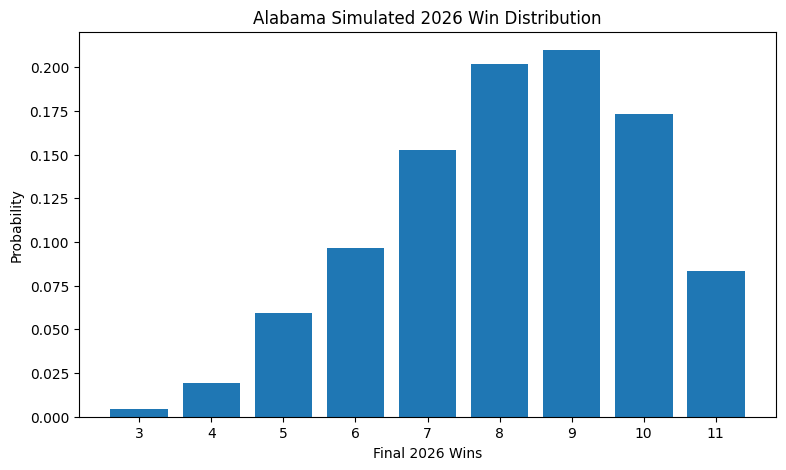

In [259]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    alabama_distribution['final_wins'],
    alabama_distribution['probability']
)

plt.xlabel('Final 2026 Wins')
plt.ylabel('Probability')
plt.title('Alabama Simulated 2026 Win Distribution')
plt.xticks(alabama_distribution['final_wins'])
plt.show()

In [260]:
alabama_distribution

,final_wins,probability
0,3,0.0044
1,4,0.0194
2,5,0.0596
3,6,0.0964
4,7,0.1524
5,8,0.2018
6,9,0.2098
7,10,0.1730
8,11,0.0832


In [261]:
alabama_distribution['probability_percent'] = (
    alabama_distribution['probability'] * 100
).round(2)

alabama_distribution

,final_wins,probability,probability_percent
0,3,0.0044,0.44
1,4,0.0194,1.94
2,5,0.0596,5.96
3,6,0.0964,9.64
4,7,0.1524,15.24
5,8,0.2018,20.18
6,9,0.2098,20.98
7,10,0.1730,17.30
8,11,0.0832,8.32


In [262]:
for threshold in [8, 9, 10, 11, 12]:
    probability = (
        alabama_final_wins >= threshold
    ).mean()
    
    print(
        f"Probability of {threshold}+ wins: "
        f"{probability:.1%}"
    )

Probability of 8+ wins: 66.8%
Probability of 9+ wins: 46.6%
Probability of 10+ wins: 25.6%
Probability of 11+ wins: 8.3%
Probability of 12+ wins: 0.0%
